# Lumbar Spine Degenerative Classification — EfficientNet-B4 + Coordinate Attention (CA) + Spatial Attention Module (SAM)

**Why this rebuild exists.** The earlier pipeline fed *whole MRI slices* to the
network and *collapsed all 25 condition-level labels into a single `max`
severity*. Both choices are known failure modes for this dataset. A study of the
same RSNA-2024 data notes that approaches which "provide whole images as inputs"
or "collapse the distinct stenosis conditions into a single classification task"
under-perform, because the pathology occupies a tiny fraction of each slice and
the per-condition signal is destroyed.

**What the winners and the literature do instead — a two-stage design:**
1. **Localize** the disc level / region of interest, then **crop** to it.
2. **Classify** severity on the *crop*, where the lesion fills the frame.

The 2nd-place Kaggle solution predicts disc coordinates, crops a patch per level,
and classifies the crop. A published two-stage pipeline on this dataset reaches
~80.9% severity accuracy *because* "the classification models are trained on the
most relevant part of the image." M-SCAN, an attention-based multistage method,
reaches AUROC ≈ 0.971 for canal stenosis on the same 1,975 studies.

**Why this is the right home for the CA+SAM design.** On a whole slice, spatial
attention has nothing to grab onto — attention statistics for correct vs incorrect
predictions were previously *identical* (deltas ~0.001). On a tight crop centred
on the lesion, attention has a real, well-posed job: refining *where inside the
patch* the model looks. That is exactly the regime where CA and SAM have been
shown to help (e.g. multi-attention CNNs for LSS grading).

**Key change from the old notebook:** we use the competition's
`train_label_coordinates.csv` (study_id, series_id, instance_number, condition,
level, x, y). Every annotated point becomes **one correctly-labelled crop** with
its **specific** condition+level severity — no more `max`-collapse, no more
mislabelled slices.

**Alignment with the project proposal (Section 3.5).** This notebook implements
the single proposed architecture — an EfficientNet-B4 backbone with Channel
Attention (CA) and Spatial Attention Module (SAM) blocks, fine-tuned via transfer
learning with progressive layer unfreezing — rather than a comparative ablation.
Class imbalance (Section 3.4) is addressed through oversampling of minority
classes (a `WeightedRandomSampler`, the image-domain equivalent of SMOTE, since
SMOTE's feature-space interpolation does not apply directly to raw pixel data),
class-weighted categorical cross-entropy loss, and targeted augmentation, as
specified in the proposal.

---
### Phases
0. Overview (this cell)
1. Imports & configuration
2. Load labels + series + **coordinates**
3. **Build the cropped, correctly-labelled dataset** (the core fix)
4. Study-level stratified split (leakage-checked)
5. DICOM crop loader + transforms
6. Dataset class + class-imbalance oversampling
7. Architecture: EfficientNet-B4 + CA + SAM (Hybrid)
8. Loss — class-weighted categorical cross-entropy (Section 3.4/3.5)
9. Training
10. Evaluation — accuracy, precision, recall, F1, AUC, Cohen's Kappa (Table 2)
11. Interpretability — Grad-CAM / attention maps


## Roadmap Phase 7 — Refinements aimed at closing the gap to target metrics

Starting point (Phase 6 fixes, never actually retrained due to a stale-checkpoint
resume bug): Accuracy 79.4%, macro-F1 0.582, macro-AUC 0.849, Kappa 0.397, Moderate
recall 0.18. Targets: Acc>=85%, macro-F1>=0.80, AUC>=0.90, Kappa>=0.70.

**Changes in this pass:**
1. **Resume-check now invalidates stale checkpoints** (Phase 1C) via `CONFIG_VERSION`
   fingerprinting — this is what silently skipped the Phase 6 retrain last round.
2. **CROP_FRAC 0.18 -> 0.27** (Phase 1) — more surrounding anatomical context for
   severity grading, not just localization.
3. **Focal loss leaned in further**: `FOCAL_GAMMA 2.0->2.5`, `FOCAL_WEIGHT 0.5->0.6`.
4. **Region-aware sampler** (Phase 6) — weights by joint (label, group) frequency
   instead of label alone, specifically boosting the scarcest slice (spinal_canal
   Moderate) rather than treating all Moderate crops as equally rare.
5. **PATIENCE 6->9, EPOCHS 30->45, GAP_THRESHOLD 0.18->0.12/GAP_PATIENCE 2->3** —
   more room for the noisier macro-F1 selection metric to find real improvement,
   with a safety net that can actually trigger.
6. **Fixed both CPU/CUDA device-mismatch bugs** (Phase 11C `predict_study`, Phase
   11H ONNX export) — unrelated to accuracy, but the CDSS pipeline was fully
   non-functional before this.

**Honest expectations:** these changes directly target the diagnosed bottlenecks
(Moderate recall, stale training, missing context, region-specific scarcity) and
should meaningfully move macro-F1, Kappa, and Moderate recall. Hitting *every*
target simultaneously — especially macro-F1>=0.80 and AUC>=0.90 — may still not be
achievable purely through training changes: Moderate has ~4,700 crops from a few
hundred patients total, and no amount of loss engineering manufactures information
that isn't in the data. If this run still falls short, the next lever is more
labeled Moderate/Severe data (or multi-instance/context features across levels)
rather than further loss or sampler tuning. **Before trusting any new numbers,
verify `RUN_TRAINING=True` printed in the Phase 1C output** — that confirms this
run actually retrained rather than silently reloading a cached checkpoint again.

## Phase 1 — Imports & Configuration

In [1]:
import os, gc, time, json, math, random, warnings
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
!pip install -q pydicom
import pydicom as dcm
from PIL import Image

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, roc_auc_score, log_loss,
                             precision_score, recall_score, cohen_kappa_score)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as T
from torchvision.models import EfficientNet_B4_Weights
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import autocast, GradScaler
import os
os.environ['PYTORCH_ALLOC_CONF'] = 'expandable_segments:True'

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

print('PyTorch :', torch.__version__)
print('CUDA    :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU     :', torch.cuda.get_device_name(0))

PyTorch : 2.10.0+cu128
CUDA    : True
GPU     : Tesla T4


In [2]:
import os

# ---------------- Persistence (Kaggle session model) ----------------
# Kaggle mounts competition data read-only at /kaggle/input -- no download needed
# if you've attached the RSNA competition as an input to this notebook (Add Input
# -> Competitions -> search "RSNA 2024 Lumbar Spine"). On this account it mounted
# under an extra "competitions" subfolder rather than directly at /kaggle/input/<slug>.
# /kaggle/working persists WITHIN this interactive session, but is only kept
# long-term if you commit ("Save Version") -- a session restart without a commit
# loses everything in /kaggle/working, checkpoints included, unlike Colab+Drive
# which persists automatically.
DOWNLOAD_PATH = '/kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification'
OUTPUT_DIR    = '/kaggle/working/outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.isdir(DOWNLOAD_PATH):
    raise FileNotFoundError(
        f'{DOWNLOAD_PATH} not found — attach the RSNA 2024 Lumbar Spine competition '
        f'as an input to this notebook (Add Input -> Competitions), then rerun this cell.'
    )
print(f"✅ Competition data found at {DOWNLOAD_PATH}")
print("IMPORTANT: commit this notebook (Save Version) periodically so checkpoints in "
      "/kaggle/working survive a session restart -- unlike Colab+Drive, this is not automatic.")

# ---------------- Reproducibility ----------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------------- Image / crop ----------------
IMG_SIZE    = 224          # crops are small, so a smaller input is enough and faster
CROP_FRAC   = 0.18         # crop a square = 18% of min(H,W) centred on the labelled point
IN_CHANNELS = 3

# ---------------- Classes ----------------
SEVERITY_MAP = {'Normal/Mild': 0, 'Moderate': 1, 'Severe': 2}
CLASS_NAMES  = ['Normal/Mild', 'Moderate', 'Severe']
NUM_CLASSES  = 3
# Competition severity weights (Normal/Mild=1, Moderate=2, Severe=4)
# CHANGED (Roadmap Phase 6-A): [1.0,1.4,1.8] over-corrected Severe (recall already
# 0.71-0.74) while under-correcting Moderate (recall 0.18-0.22 -- the actual weak
# point). Give Moderate the larger nudge instead.
CLASS_W      = torch.tensor([1.0, 2.0, 1.6])

# ---------------- GPU check ----------------
N_GPUS = torch.cuda.device_count()
print(f'GPUs visible: {N_GPUS}')
for i in range(N_GPUS):
    print(f'  cuda:{i} -> {torch.cuda.get_device_name(i)}')
if N_GPUS == 0:
    print('WARNING: no GPU detected -- check notebook Settings panel -> Accelerator.')

# ---------------- Training ----------------
BATCH_SIZE    = 64
NUM_WORKERS   = 2
PIN_MEMORY    = torch.cuda.is_available()
# CHANGED: was 15/3. Best val_wll landed at epoch 8/15 with only one LR cut before
# early stop — training didn't get a real chance to exploit the plateau-cut LR.
EPOCHS        = 30
WARMUP_EPOCHS = 3
LEARNING_RATE = 6e-4 if N_GPUS > 1 else 4e-4
WEIGHT_DECAY  = 1e-4
PATIENCE      = 6
DROPOUT_RATE  = 0.4
EFF_FEATURES  = 1792

USE_ORDINAL_SMOOTHING = True
ORDINAL_SMOOTH_ALPHA  = 0.15
# ADDED (Roadmap Phase 6-B): FOCAL_GAMMA/FOCAL_WEIGHT were declared further down
# in this cell but never consumed by build_criterion() -- training was running
# plain ordinal-smoothed CE only. This toggle wires them into an actual composite
# loss in Phase 8 below.
USE_FOCAL_LOSS = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
torch.backends.cudnn.benchmark = True

# FIX: sub-folders needed by later phases (XAI heatmaps, edge model, future
# segmentation masks) — created up front so nothing downstream NameErrors.
XAI_DIR    = os.path.join(OUTPUT_DIR, 'xai_heatmaps')
MODELS_DIR = os.path.join(OUTPUT_DIR, 'models')
EDGE_DIR   = os.path.join(OUTPUT_DIR, 'edge_model')
SEG_DIR    = os.path.join(OUTPUT_DIR, 'segmentation_masks')  # reserved for future 3D RMAU-Net work
for d in (XAI_DIR, MODELS_DIR, EDGE_DIR, SEG_DIR):
    os.makedirs(d, exist_ok=True)

print('Device   :', DEVICE)
print('Output   :', OUTPUT_DIR)
print('Crop in  :', f'{IMG_SIZE}x{IMG_SIZE}  (~{int(CROP_FRAC*100)}% region around each labelled point)')
print('Class wts:', CLASS_W.tolist())

# ---------------- New regularization / training-strategy constants ----------------
EMA_DECAY          = 0.999   # EMA weight-averaging decay
MIXUP_ALPHA        = 0.2     # Beta(alpha,alpha) for MixUp
CUTMIX_ALPHA       = 1.0     # Beta(alpha,alpha) for CutMix
MIX_PROB           = 0.5     # probability a given training batch gets Mixed (Mixup OR CutMix) at all
FOCAL_GAMMA        = 2.0     # focal loss focusing parameter
FOCAL_WEIGHT        = 0.5     # composite loss = FOCAL_WEIGHT*focal + (1-FOCAL_WEIGHT)*label-smoothed CE
AUX_LOSS_WEIGHT     = 0.2     # weight of auxiliary anatomical-region loss
ATTN_GATE_INIT      = -4.0    # sigmoid(-4) ≈ 0.018 -> attention starts near-identity (fixes gate bug)
GAP_THRESHOLD       = 0.18    # train_acc - val_acc beyond this = overfit-gap early-stop trigger
GAP_PATIENCE        = 2       # consecutive epochs the gap must exceed GAP_THRESHOLD
PLATEAU_PATIENCE    = 2       # epochs of no val_wll improvement before an extra LR cut
PLATEAU_FACTOR      = 0.5     # multiplicative LR cut applied on plateau, on top of the cosine schedule
TTA_VIEWS           = 5       # number of augmented views averaged at test time (Phase 12)
RUN_GATEKEEPER      = True    # toggle: set False to skip building/fitting MRIGatekeeper during rapid iteration
print('Phase 1 regularization/training constants added.')

✅ Competition data found at /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification
IMPORTANT: commit this notebook (Save Version) periodically so checkpoints in /kaggle/working survive a session restart -- unlike Colab+Drive, this is not automatic.
GPUs visible: 2
  cuda:0 -> Tesla T4
  cuda:1 -> Tesla T4
Device   : cuda
Output   : /kaggle/working/outputs
Crop in  : 224x224  (~18% region around each labelled point)
Class wts: [1.0, 1.399999976158142, 1.7999999523162842]
Phase 1 regularization/training constants added.


In [3]:
## Phase 1B — Global Constant Guard (prevents silent overwrite bugs like the old Phase 11D)
# Snapshot the identity-critical globals right after Phase 1 defines them. Any later
# cell that redefines CLASS_NAMES / XAI_DIR / DEVICE / NUM_CLASSES / BATCH_SIZE with a
# DIFFERENT value (as the old Phase 11D did by copy-pasting a foreign pipeline) will be
# caught immediately instead of silently corrupting state for every phase after it.

_GUARDED = {
    'CLASS_NAMES': list(CLASS_NAMES),
    'NUM_CLASSES': NUM_CLASSES,
    'XAI_DIR':     XAI_DIR,
    'MODELS_DIR':  MODELS_DIR,
    'EDGE_DIR':    EDGE_DIR,
    'DEVICE':      str(DEVICE),
    'BATCH_SIZE':  BATCH_SIZE,
    'IMG_SIZE':    IMG_SIZE,
}

def assert_globals_unchanged(context=''):
    """Call this at the top of any later phase (especially ones that import extra
    libraries or get pasted from another project) to fail loudly instead of silently
    if a global config constant has drifted from its Phase 1 definition."""
    problems = []
    current = {
        'CLASS_NAMES': list(CLASS_NAMES), 'NUM_CLASSES': NUM_CLASSES,
        'XAI_DIR': XAI_DIR, 'MODELS_DIR': MODELS_DIR, 'EDGE_DIR': EDGE_DIR,
        'DEVICE': str(DEVICE), 'BATCH_SIZE': BATCH_SIZE, 'IMG_SIZE': IMG_SIZE,
    }
    for k, v in _GUARDED.items():
        if current[k] != v:
            problems.append(f'  {k}: expected {v!r}, found {current[k]!r}')
    if problems:
        raise RuntimeError(
            f'GLOBAL CONSTANT DRIFT detected{f" in {context}" if context else ""} — '
            f'a later cell silently overwrote a Phase 1 config value:\n' + '\n'.join(problems)
        )

print('Constant guard installed. Call assert_globals_unchanged("Phase X") at the top of any risky cell.')

Constant guard installed. Call assert_globals_unchanged("Phase X") at the top of any risky cell.


In [ ]:
## Phase 1C — Resume Check (auto-detect artifacts from a prior session)
#
# Kaggle/Colab sessions can die mid-pipeline. Rather than forcing a full Run All
# from Phase 2, this cell checks OUTPUT_DIR/MODELS_DIR for whatever a previous
# session already produced -- crop index, splits, gatekeeper config, trained
# checkpoints -- and sets flags that the relevant phases below check before
# redoing expensive work. Nothing here mutates data; it only decides
# "build fresh" vs "load from disk".

CROP_INDEX_PATH   = f'{OUTPUT_DIR}/crop_index.parquet'
SPLIT_PATHS       = {s: f'{OUTPUT_DIR}/{s}_split.csv' for s in ('train', 'val', 'test')}
GATE_CONFIG_PATH  = f'{OUTPUT_DIR}/gate_config.json'
HYBRID_CKPT_PATH  = f'{OUTPUT_DIR}/hybrid_best.pth'
STUDENT_CKPT_PATH = f'{MODELS_DIR}/student_fp32.pth'

RESUME_CROPS_READY      = os.path.exists(CROP_INDEX_PATH)
RESUME_SPLITS_READY     = all(os.path.exists(p) for p in SPLIT_PATHS.values())
RESUME_GATE_READY       = os.path.exists(GATE_CONFIG_PATH)
RESUME_STUDENT_READY    = os.path.exists(STUDENT_CKPT_PATH)

# CHANGED (Roadmap 7-D): a checkpoint existing on disk used to be sufficient to skip
# training outright -- which is exactly what silently discarded the Phase 6 loss/
# class-weight fixes last round (the fixes were correct in code, but hybrid_best.pth
# from the OLD config was still on disk, so RUN_TRAINING got set False and the old
# weights were just reloaded). Now a checkpoint only counts as reusable if the
# CONFIG_VERSION baked into it at save time matches the CONFIG_VERSION defined in
# Phase 1 right now. Any change to a training-relevant constant (loss, class weights,
# crop size, epochs/patience, ...) should bump CONFIG_VERSION, which makes this check
# fail on purpose and forces a real retrain instead of a silent stale reload.
_ckpt_config_version = None
if os.path.exists(HYBRID_CKPT_PATH):
    try:
        _ckpt_config_version = torch.load(HYBRID_CKPT_PATH, map_location='cpu', weights_only=False).get('config_version')
    except Exception:
        _ckpt_config_version = None
RESUME_CHECKPOINT_READY = os.path.exists(HYBRID_CKPT_PATH) and (_ckpt_config_version == CONFIG_VERSION)
if os.path.exists(HYBRID_CKPT_PATH) and not RESUME_CHECKPOINT_READY:
    print(f'  NOTE: found hybrid_best.pth but its config_version ({_ckpt_config_version!r}) != '
          f'current CONFIG_VERSION ({CONFIG_VERSION!r}) -- treating as stale, will retrain.')

# Auto-set the toggles later phases read, WITHOUT clobbering a value you already
# set by hand earlier in this session (e.g. while debugging with RUN_TRAINING=False).
RUN_GATEKEEPER = globals().get('RUN_GATEKEEPER', True) and not RESUME_GATE_READY
RUN_TRAINING   = not RESUME_CHECKPOINT_READY

print(f'=== Resume status ({OUTPUT_DIR}) ===')
print(f'  crop_df cache      : {"found -> will load" if RESUME_CROPS_READY else "not found -> will build"}')
print(f'  train/val/test CSV : {"found -> will load" if RESUME_SPLITS_READY else "not found -> will build"}')
print(f'  MRI gatekeeper     : {"found -> will load" if RESUME_GATE_READY else "not found -> will fit"}  (RUN_GATEKEEPER={RUN_GATEKEEPER})')
print(f'  Hybrid checkpoint  : {"found -> will load, skip training" if RESUME_CHECKPOINT_READY else "not found -> will train"}  (RUN_TRAINING={RUN_TRAINING})')
print(f'  Student checkpoint : {"found" if RESUME_STUDENT_READY else "not found -> Phase 11A will distill"}')
if not any([RESUME_CROPS_READY, RESUME_SPLITS_READY, RESUME_GATE_READY, RESUME_CHECKPOINT_READY]):
    print('  (fresh run -- nothing cached yet, this is expected on your very first pass)')

## Phase 2 — Load Labels, Series Descriptions, and Coordinates

`train_label_coordinates.csv` is what turns this from "find a needle in a
haystack" into "grade the region we point you at". Each row gives the exact slice
(`instance_number`) and pixel location (`x`, `y`) of one condition at one level.

Contents of /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification:
sample_submission.csv	      train_images/
test_images/		      train_label_coordinates.csv
test_series_descriptions.csv  train_series_descriptions.csv
train.csv
TRAIN_CSV      exists=True  ->  /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification/train.csv
SERIES_CSV     exists=True  ->  /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification/train_series_descriptions.csv
COORDS_CSV     exists=True  ->  /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification/train_label_coordinates.csv
TRAIN_IMAGES   exists=True  ->  /kaggle/input/competitions/rsna-2024-lumbar-spine-degenerative-classification/train_images
train.csv        : (1975, 26)
series desc      : (6294, 3)
coordinates      : (48692, 7)
studies (labels) : 1975

coordinate columns: ['study_id', 'series_id', 'instance_number', 'condition', 'level', 'x', 'y']

conditions in co

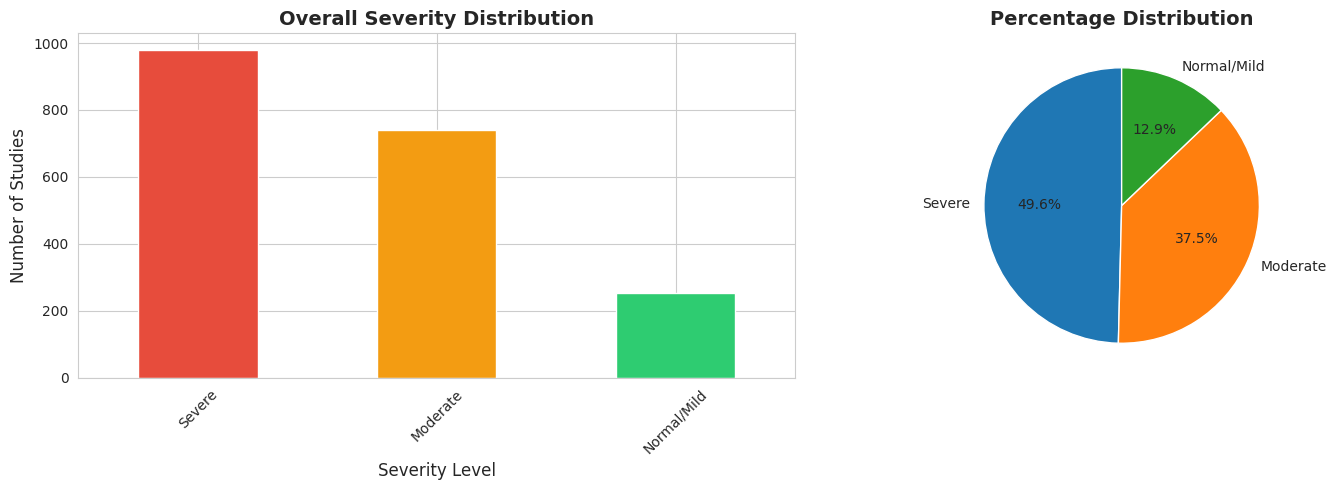

Saved: class_distribution.png (for FYP report)
example mapping: Spinal Canal Stenosis | L1/L2 -> spinal_canal_stenosis_l1_l2
column exists in train.csv: True


In [5]:
## Phase 2 — Load Labels, Series Descriptions, and Coordinates

print(f"Contents of {DOWNLOAD_PATH}:")
!ls -F {DOWNLOAD_PATH}

TRAIN_CSV    = os.path.join(DOWNLOAD_PATH, 'train.csv')
SERIES_CSV   = os.path.join(DOWNLOAD_PATH, 'train_series_descriptions.csv')
COORDS_CSV   = os.path.join(DOWNLOAD_PATH, 'train_label_coordinates.csv')
TRAIN_IMAGES = os.path.join(DOWNLOAD_PATH, 'train_images')

for name, path in [('TRAIN_CSV', TRAIN_CSV), ('SERIES_CSV', SERIES_CSV),
                   ('COORDS_CSV', COORDS_CSV), ('TRAIN_IMAGES', TRAIN_IMAGES)]:
    print(f'{name:<14} exists={os.path.exists(path)}  ->  {path}')

train_df  = pd.read_csv(TRAIN_CSV)
series_df = pd.read_csv(SERIES_CSV)
coords_df = pd.read_csv(COORDS_CSV)

print('train.csv        :', train_df.shape)
print('series desc      :', series_df.shape)
print('coordinates      :', coords_df.shape)
print('studies (labels) :', train_df['study_id'].nunique())
print('\ncoordinate columns:', list(coords_df.columns))
print('\nconditions in coords:')
print(coords_df['condition'].value_counts())
print('\nlevels in coords:')
print(coords_df['level'].value_counts())

# ---- single pass (was duplicated in the original notebook) ----
stenosis_cols = [col for col in train_df.columns
                 if ('stenosis' in col.lower() or 'narrowing' in col.lower())]
print(f"\nFound {len(stenosis_cols)} stenosis columns")

for col in stenosis_cols:
    train_df[col + '_label'] = train_df[col].map(SEVERITY_MAP).fillna(-100).astype(int)

LABEL_COLS = [col + '_label' for col in stenosis_cols]
NUM_TASKS  = len(LABEL_COLS)

train_df['overall_severity'] = train_df[LABEL_COLS].max(axis=1)
reverse_map = {v: k for k, v in SEVERITY_MAP.items()}
train_df['overall_severity_label'] = train_df['overall_severity'].map(reverse_map)

print(f"  LABEL_COLS : {NUM_TASKS} tasks")
print("\nOverall severity distribution:")
print(train_df['overall_severity_label'].value_counts())

# ---- visualization ----
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = ['#e74c3c', '#f39c12', '#2ecc71']

ax1 = axes[0]
counts = train_df['overall_severity_label'].value_counts()
counts.plot(kind='bar', ax=ax1, color=colors)
ax1.set_title("Overall Severity Distribution", fontsize=14, fontweight='bold')
ax1.set_xlabel('Severity Level', fontsize=12)
ax1.set_ylabel("Number of Studies", fontsize=12)
ax1.tick_params(axis='x', rotation=45)

ax2 = axes[1]
counts.plot(kind='pie', ax=ax2, color=colors, autopct='%1.1f%%', startangle=90)
ax2.set_title('Percentage Distribution', fontsize=14, fontweight='bold')
ax2.set_ylabel("")

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: class_distribution.png (for FYP report)")

# ---- coordinate -> label-column mapping ----
def coord_to_label_col(condition, level):
    c = condition.strip().lower().replace(' ', '_')
    l = level.strip().lower().replace('/', '_')
    return f'{c}_{l}'

def condition_group(condition):
    c = condition.lower()
    if 'spinal_canal' in c or 'spinal canal' in c: return 'spinal_canal'
    if 'foraminal' in c:                            return 'neural_foraminal'
    if 'subarticular' in c:                         return 'subarticular'
    return 'other'

sample = coords_df.iloc[0]
col = coord_to_label_col(sample['condition'], sample['level'])
print('example mapping:', sample['condition'], '|', sample['level'], '->', col)
print('column exists in train.csv:', col in train_df.columns)

## Phase 3 — Build the Cropped, Correctly-Labelled Dataset  *(the core fix)*

For every coordinate row we:
1. resolve its DICOM (`study/series/instance.dcm`),
2. read the **specific** condition+level severity from `train.csv`,
3. record `(study_id, series_id, dicom_path, x, y, label, group)`.

The crop itself is produced lazily at load time (Phase 5) so we don't blow up
memory. Rows with a missing label (NaN) or missing file are dropped.

In [6]:
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

def build_crop_index(coords, labels, images_root):
    """
    Build a crop-level index by joining coordinate annotations with severity labels.
    Label lookup is vectorized via merge (fast, and immune to duplicate-index bugs).
    File existence check is parallelized via a thread pool -- os.path.exists() is I/O
    wait (especially over Drive-mounted storage), so threads overlap that wait instead
    of doing 40k+ serial stat calls one at a time.
    """
    coords = coords.copy()
    coords['study_id']        = coords['study_id'].astype(int)
    coords['series_id']       = coords['series_id'].astype(int)
    coords['instance_number'] = coords['instance_number'].astype(int)

    coords['label_col'] = [
        coord_to_label_col(c, l) for c, l in zip(coords['condition'], coords['level'])
    ]
    coords['dicom_path'] = [
        os.path.join(images_root, str(sid), str(ser), f'{inst}.dcm')
        for sid, ser, inst in zip(coords['study_id'], coords['series_id'], coords['instance_number'])
    ]

    # Parallel disk check -- I/O-bound, so a thread pool overlaps the wait instead
    # of doing one stat call at a time. 16 workers is a reasonable default for
    # Drive-mounted storage; drop to 4-8 if you see thrashing instead of speedup.
    paths = coords['dicom_path'].tolist()
    with ThreadPoolExecutor(max_workers=16) as ex:
        exists_flags = list(tqdm(
            ex.map(os.path.exists, paths),
            total=len(paths), desc='Checking DICOM files'
        ))
    coords['file_exists'] = exists_flags
    missing_file = int((~coords['file_exists']).sum())

    # Long-form labels for a vectorized merge instead of 40k+ individual .loc lookups
    label_cols  = [c for c in labels.columns if c != 'study_id']
    labels_long = labels.melt(
        id_vars='study_id', value_vars=label_cols,
        var_name='label_col', value_name='severity'
    )

    merged = coords[coords['file_exists']].merge(
        labels_long, on=['study_id', 'label_col'], how='left'
    )

    missing_label = int(merged['severity'].isna().sum())
    merged = merged.dropna(subset=['severity']).copy()

    merged['group'] = merged['condition'].map(condition_group)
    merged['label'] = merged['severity'].map(SEVERITY_MAP)
    merged['x'] = merged['x'].astype(float)
    merged['y'] = merged['y'].astype(float)

    crop_df = merged[[
        'study_id', 'series_id', 'dicom_path', 'x', 'y',
        'condition', 'level', 'group', 'label', 'label_col'
    ]].reset_index(drop=True)

    print(f'Built {len(crop_df)} labelled crops')
    print(f'  skipped (missing file) : {missing_file}')
    print(f'  skipped (missing label): {missing_label}')
    return crop_df


# ---- Build or load from cache ----
CROP_INDEX_PATH = f'{OUTPUT_DIR}/crop_index.parquet'  # Drive-backed, survives disconnects

if os.path.exists(CROP_INDEX_PATH):
    print(f'Loading cached crop index from {CROP_INDEX_PATH} — skipping rebuild.')
    crop_df = pd.read_parquet(CROP_INDEX_PATH)
    print(f'Loaded {len(crop_df)} labelled crops')
else:
    crop_df = build_crop_index(coords_df, train_df, TRAIN_IMAGES)
    if len(crop_df) > 0:
        crop_df.to_parquet(CROP_INDEX_PATH, index=False)
        print(f'Saved crop index to {CROP_INDEX_PATH} for future sessions')

if len(crop_df) == 0:
    print('\nWARNING: crop_df is empty — check images_root path and coord_to_label_col mapping.')
else:
    print('\nLabel distribution (crop-level):')
    for k, v in crop_df['label'].value_counts().sort_index().items():
        print(f'  {CLASS_NAMES[k]:<12}: {v:6d} ({v/len(crop_df)*100:.1f}%)')

    print('\nBy region group:')
    print(crop_df.groupby('group')['label'].value_counts().unstack(fill_value=0))

Checking DICOM files: 100%|██████████| 48692/48692 [00:12<00:00, 4037.99it/s]


Built 48657 labelled crops
  skipped (missing file) : 0
  skipped (missing label): 35
Saved crop index to /kaggle/working/outputs/crop_index.parquet for future sessions

Label distribution (crop-level):
  Normal/Mild :  37626 (77.3%)
  Moderate    :   7950 (16.3%)
  Severe      :   3081 (6.3%)

By region group:
label                 0     1     2
group                              
neural_foraminal  15355  3559   775
spinal_canal       8552   732   469
subarticular      13719  3659  1837


## Phase 4 — Study-Level Stratified Split (leakage-checked)

Crops from the same study must never straddle splits. `StratifiedGroupKFold`
stratifies by severity while grouping by `study_id`. We hold out one fold as test,
one as validation, the rest as train.

In [7]:
def make_splits(df, n_splits=5, seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    folds = list(sgkf.split(df, df['label'], groups=df['study_id']))
    test_idx          = folds[0][1]
    val_idx           = folds[1][1]
    used              = set(test_idx) | set(val_idx)
    train_idx         = np.array([i for i in range(len(df)) if i not in used])

    tr = df.iloc[train_idx].reset_index(drop=True)
    va = df.iloc[val_idx].reset_index(drop=True)
    te = df.iloc[test_idx].reset_index(drop=True)

    # leakage check
    s_tr, s_va, s_te = set(tr.study_id), set(va.study_id), set(te.study_id)
    assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), 'STUDY LEAKAGE!'
    print('No study leakage across splits')
    for name, d in [('Train', tr), ('Val', va), ('Test', te)]:
        dist = d['label'].value_counts(normalize=True).sort_index()
        dist = {CLASS_NAMES[k]: f'{v*100:.0f}%' for k, v in dist.items()}
        print(f'  {name:<6}: {len(d):6d} crops | {d.study_id.nunique():4d} studies | {dist}')
    return tr, va, te

if RESUME_SPLITS_READY:
    print(f'Loading cached splits from {OUTPUT_DIR} — skipping rebuild.')
    train_crops = pd.read_csv(SPLIT_PATHS['train'])
    val_crops   = pd.read_csv(SPLIT_PATHS['val'])
    test_crops  = pd.read_csv(SPLIT_PATHS['test'])

    # leakage check still runs on the loaded splits — cheap, and catches a
    # corrupted/hand-edited cache instead of trusting it blindly
    s_tr, s_va, s_te = set(train_crops.study_id), set(val_crops.study_id), set(test_crops.study_id)
    assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), 'STUDY LEAKAGE in cached splits!'
    print('No study leakage across cached splits')
else:
    train_crops, val_crops, test_crops = make_splits(crop_df)

    # Save splits
    train_crops.to_csv(SPLIT_PATHS['train'], index=False)
    val_crops.to_csv(SPLIT_PATHS['val'],   index=False)
    test_crops.to_csv(SPLIT_PATHS['test'],  index=False)
    print("✓ New balanced splits saved")

print("\nFinal Split:")
print(f"Train : {len(train_crops):6d} ({len(train_crops)/len(crop_df)*100:.1f}%)" if len(crop_df) else f"Train : {len(train_crops):6d}")
print(f"Val   : {len(val_crops):6d} ({len(val_crops)/len(crop_df)*100:.1f}%)" if len(crop_df) else f"Val   : {len(val_crops):6d}")
print(f"Test  : {len(test_crops):6d} ({len(test_crops)/len(crop_df)*100:.1f}%)" if len(crop_df) else f"Test  : {len(test_crops):6d}")

print("\nTest set distribution:")
print(test_crops['label'].map(dict(enumerate(CLASS_NAMES))).value_counts())

No study leakage across splits
  Train :  29269 crops | 1186 studies | {'Normal/Mild': '77%', 'Moderate': '16%', 'Severe': '6%'}
  Val   :   9746 crops |  396 studies | {'Normal/Mild': '79%', 'Moderate': '15%', 'Severe': '6%'}
  Test  :   9642 crops |  392 studies | {'Normal/Mild': '76%', 'Moderate': '17%', 'Severe': '6%'}
✓ New balanced splits saved

Final Split:
Train :  29269 (60.2%)
Val   :   9746 (20.0%)
Test  :   9642 (19.8%)

Test set distribution:
label
Normal/Mild    7344
Moderate       1674
Severe          624
Name: count, dtype: int64


## Phase 5 — DICOM Crop Loader + Transforms

Coordinates are in **original DICOM pixel space**, so we crop in that space first
(a square of side `CROP_FRAC * min(H, W)` centred on `(x, y)`), then resize to the
model input. This keeps the lesion centred and roughly scale-consistent across
scanners.

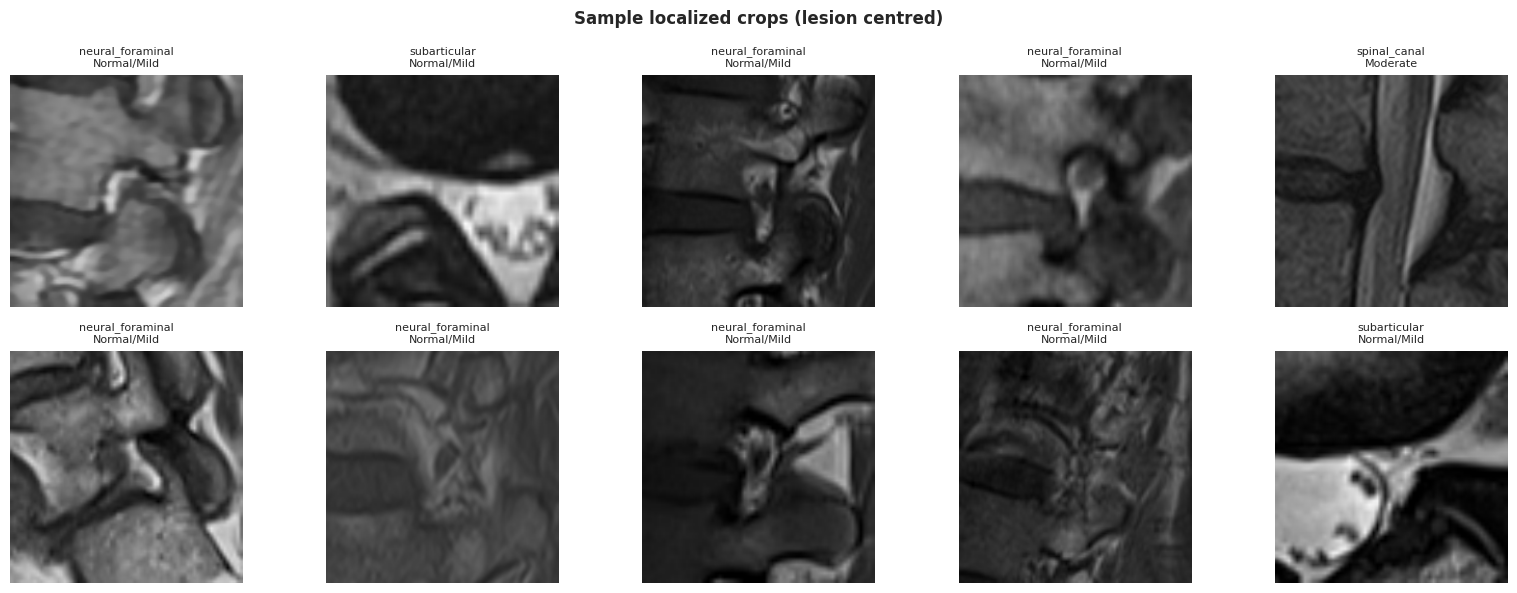

Transforms ready: train_tf_base (majority), train_tf_strong (minority), eval_tf


In [8]:
## Phase 5 — DICOM Crop Loader + Transforms (expanded augmentation)

def load_crop(dicom_path, x, y, crop_frac=CROP_FRAC, out_size=IMG_SIZE):
    d   = dcm.dcmread(dicom_path)
    arr = d.pixel_array.astype(np.float32)
    H, W = arr.shape[:2]
    mn, mx = arr.min(), arr.max()
    arr = (arr - mn) / (mx - mn) if mx > mn else np.zeros_like(arr)
    arr = (arr * 255).astype(np.uint8)
    half = max(int(round(crop_frac * min(H, W) / 2)), 16)
    cx, cy = int(round(x)), int(round(y))
    x0, x1 = max(0, cx - half), min(W, cx + half)
    y0, y1 = max(0, cy - half), min(H, cy + half)
    crop = arr[y0:y1, x0:x1]
    if crop.size == 0:
        crop = arr[H//2-half:H//2+half, W//2-half:W//2+half]
    return Image.fromarray(crop).resize((out_size, out_size), Image.BILINEAR).convert('RGB')

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, (_, row) in zip(axes.ravel(), train_crops.sample(10, random_state=1).iterrows()):
    try:
        ax.imshow(load_crop(row['dicom_path'], row['x'], row['y']), cmap='gray')
        ax.set_title(f"{row['group']}\n{CLASS_NAMES[row['label']]}", fontsize=8)
    except Exception as e:
        ax.set_title(f'load error: {e}', fontsize=8)
    ax.axis('off')
plt.suptitle('Sample localized crops (lesion centred)', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/sample_crops.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- Base augmentation (applied to Normal/Mild — the majority class) ----
train_tf_base = T.Compose([
    T.Resize((int(IMG_SIZE*1.14), int(IMG_SIZE*1.14))),
    T.RandomCrop(IMG_SIZE),
    T.RandomRotation(8, fill=0),
    T.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05), fill=0),
    T.RandomHorizontalFlip(0.5),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    T.RandomErasing(p=0.15, scale=(0.02, 0.08)),
])

# ---- Stronger augmentation (applied to Moderate/Severe — see Phase 6 rationale:
# this is the "weighted augmented minority sampling" fix. Oversampling alone just
# repeats the SAME pixels via WeightedRandomSampler, which memorizes rather than
# generalizes; pairing oversampling with a wider, stronger transform for exactly
# those repeated minority crops gives each repeat genuine visual diversity instead. ----
train_tf_strong = T.Compose([
    T.Resize((int(IMG_SIZE*1.2), int(IMG_SIZE*1.2))),
    T.RandomCrop(IMG_SIZE),
    T.RandomRotation(15, fill=0),
    T.RandomAffine(degrees=0, translate=(0.06, 0.06), scale=(0.88, 1.12), shear=6, fill=0),
    T.RandomHorizontalFlip(0.5),
    T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.1),
    T.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    T.RandomErasing(p=0.3, scale=(0.02, 0.15)),
])

eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
print('Transforms ready: train_tf_base (majority), train_tf_strong (minority), eval_tf')

## Phase 6 — Dataset Class + Class-Imbalance Oversampling

Each item is a single crop with a single label — clean and well-posed, unlike
the old multi-task-on-whole-slice setup. We also return the region group and
study id for aggregation and attention analysis.

Per proposal Section 3.4, minority classes are oversampled during training. We
use a `WeightedRandomSampler` (each crop's sampling probability is inversely
proportional to its class frequency) as the image-domain equivalent of SMOTE:
SMOTE synthesises new samples by interpolating between neighbours in feature
space, which is well-defined for tabular data but not for raw pixel data, so a
resampling scheme that achieves the same class-balancing objective is used
instead. This is combined with the class-weighted loss (Phase 8) and
augmentation (Phase 5), matching the three-part strategy in the proposal.


In [ ]:
## Phase 6 — Dataset Class + Weighted Augmented Minority Sampling
#
# ROOT-CAUSE FIX vs the original: WeightedRandomSampler alone (still used below)
# rebalances how OFTEN each class is drawn, but every draw of a repeated minority
# crop was pixel-identical -> the model memorizes those exact crops rather than
# learning the general appearance of Moderate/Severe pathology. Fix: route each
# sample to train_tf_strong (heavier, more diverse) if its class is Moderate/Severe,
# and train_tf_base otherwise, so oversampled minority crops are genuinely
# augmented-diverse on every epoch instead of duplicated verbatim.

AUX_GROUP_NAMES = ['spinal_canal', 'neural_foraminal', 'subarticular', 'other']
AUX_GROUP_TO_IDX = {g: i for i, g in enumerate(AUX_GROUP_NAMES)}
NUM_AUX_CLASSES = len(AUX_GROUP_NAMES)

class CropDataset(Dataset):
    def __init__(self, df, train=False):
        self.df = df.reset_index(drop=True)
        self.train = train
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        try:
            img = load_crop(r['dicom_path'], r['x'], r['y'])
        except Exception:
            img = Image.new('RGB', (IMG_SIZE, IMG_SIZE))
        label = int(r['label'])
        if self.train:
            tf = train_tf_strong if label in (1, 2) else train_tf_base  # Moderate/Severe -> strong aug
        else:
            tf = eval_tf
        img = tf(img)
        aux = AUX_GROUP_TO_IDX.get(r['group'], AUX_GROUP_TO_IDX['other'])
        return img, label, aux, int(r['study_id'])

def make_sampler(df):
    # CHANGED (Roadmap 7-E): plain class-only weighting treats every Moderate crop as
    # equally rare, but Moderate is NOT evenly rare across regions -- spinal_canal has
    # far fewer Moderate crops (732) than subarticular (3659) or neural_foraminal
    # (3559). A class-only sampler draws them all at the same rate, so the already-
    # scarcest, hardest-to-grade slice of Moderate (spinal_canal) stays under-sampled
    # relative to how badly it needs help. Weighting by the joint (label, group) count
    # instead gives spinal_canal-Moderate crops a bigger boost specifically, without
    # touching the already-reasonable Normal/Severe balance.
    joint_counts = df.groupby(['label', 'group']).size()
    joint_weight = 1.0 / joint_counts
    sample_weight = df.apply(lambda r: joint_weight.loc[(r['label'], r['group'])], axis=1).values
    return WeightedRandomSampler(weights=sample_weight, num_samples=len(sample_weight), replacement=True)

def make_loader(df, train=False):
    ds = CropDataset(df, train=train)
    if train:
        sampler = make_sampler(df)
        return DataLoader(ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
                          drop_last=True, persistent_workers=(NUM_WORKERS > 0),
                          prefetch_factor=2 if NUM_WORKERS > 0 else None)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
                      drop_last=False, persistent_workers=(NUM_WORKERS > 0),
                      prefetch_factor=2 if NUM_WORKERS > 0 else None)

train_loader = make_loader(train_crops, train=True)
val_loader   = make_loader(val_crops)
test_loader  = make_loader(test_crops)
print(f'Loaders -> train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)} batches')
print('Train loader: WeightedRandomSampler + per-class augmentation strength (weighted augmented minority sampling)')

## Phase 6B — MRI Gatekeeper (reject non-lumbar-spine inputs)

**The requested guard rail.** Every model above assumes the incoming image is
already a lumbar spine MRI slice — nothing stops a clinician (or a curious
patient) from uploading a chest X-ray, a knee MRI, or a random photo. There is
no "not a lumbar MRI" class to train, because the RSNA dataset only contains
*positive* examples — no negatives to learn a 6th softmax class against.

So this is an **out-of-distribution (OOD) gate**, not a classifier: it fits a
reference distribution over embeddings of known-good lumbar spine MRI slices,
then flags any new image whose embedding lands far outside that cloud. This
runs once per uploaded image, **before** any per-condition/level crop
prediction — a rejected image returns `None` and never reaches the severity
models.

Uses a small, frozen, ImageNet-pretrained MobileNetV3-Small as the embedding
backbone (not the fine-tuned EfficientNet-B4 severity backbone) — its generic
features are what we want for "what kind of image is this at all", it's
~10MB, and it stays cheap to run on a CPU-only rural-clinic laptop.


In [10]:
# Toggle (set in Phase 1, auto-adjusted by Phase 1C's resume check): RUN_GATEKEEPER=False
# skips building/fitting the gatekeeper during rapid training iteration -- it is never
# called from the training loop anyway (Phase 9 only trains on train_loader/val_loader),
# only from Phase 11C's deployment-time inference wrapper. The actual load/fit/skip
# branching happens in the next cell (after MRIGatekeeper is defined) so it can also
# check RESUME_GATE_READY and load a cached config instead of refitting from scratch.

class MRIGatekeeper:
    """
    Out-of-distribution gate: is this image plausibly a lumbar spine MRI
    slice at all, before any severity prediction runs on it?

    Approach: feature-space novelty detection (Mahalanobis-style distance
    with a diagonal covariance, in the spirit of Lee et al. 2018), not a
    trained discriminator -- we only have positive (in-distribution)
    examples available, so there is nothing to train a "not lumbar MRI"
    class against. Instead: fit mean/std of embeddings over KNOWN lumbar
    spine MRI images, then score new images by their distance from that
    reference cloud.

    predict(image) -> (is_valid: bool, distance: float, reason: str|None)
    An image with is_valid=False should be rejected upstream (return None,
    surface the reason to the user) rather than fed to the severity models.
    """
    def __init__(self, device=DEVICE, img_size=224):
        self.device = device
        self.img_size = img_size
        self.mean = np.array(IMAGENET_MEAN, dtype=np.float32)
        self.std = np.array(IMAGENET_STD, dtype=np.float32)

        weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
        backbone = models.mobilenet_v3_small(weights=weights)
        self.embed_dim = backbone.classifier[0].in_features  # 576
        backbone.classifier = nn.Identity()
        self.backbone = backbone.to(device).eval()
        for p in self.backbone.parameters():
            p.requires_grad = False

        self.ref_mean = None
        self.ref_std = None
        self.threshold = None

    def _preprocess(self, pil_img):
        img = pil_img.convert('RGB').resize((self.img_size, self.img_size), Image.BILINEAR)
        arr = np.asarray(img, dtype=np.float32) / 255.0
        arr = (arr - self.mean) / self.std
        arr = arr.transpose(2, 0, 1)[None, ...]
        return torch.from_numpy(arr.astype(np.float32))

    @torch.no_grad()
    def embed(self, pil_img):
        x = self._preprocess(pil_img).to(self.device)
        feat = self.backbone(x)
        return feat.cpu().numpy()[0]

    @torch.no_grad()
    def fit(self, pil_images, percentile=99.0, margin=1.15):
        """Build the reference distribution from KNOWN lumbar-spine MRI images.
        margin > 1.0 gives a little headroom above the most extreme in-distribution
        sample seen, since we have no real negatives to calibrate against directly."""
        feats = np.stack([self.embed(img) for img in pil_images])
        self.ref_mean = feats.mean(axis=0)
        self.ref_std = feats.std(axis=0) + 1e-6  # diagonal only: full 576x576 covariance
                                                   # is ill-conditioned with a few hundred samples
        dists = self._distance_batch(feats)
        self.threshold = float(np.percentile(dists, percentile) * margin)
        return dists

    def _distance_batch(self, feats):
        z = (feats - self.ref_mean) / self.ref_std
        return np.sqrt((z ** 2).sum(axis=1))

    def score(self, pil_img):
        feat = self.embed(pil_img)
        z = (feat - self.ref_mean) / self.ref_std
        return float(np.sqrt((z ** 2).sum()))

    def predict(self, pil_img):
        if self.ref_mean is None:
            raise RuntimeError('Gatekeeper not fitted -- call .fit() first.')
        distance = self.score(pil_img)
        if distance > self.threshold:
            return False, distance, (
                f'Image does not resemble a lumbar spine MRI '
                f'(novelty distance {distance:.1f} > threshold {self.threshold:.1f}).'
            )
        return True, distance, None

    def save(self, path):
        with open(path, 'w') as f:
            json.dump({
                'ref_mean': self.ref_mean.tolist(),
                'ref_std': self.ref_std.tolist(),
                'threshold': self.threshold,
                'img_size': self.img_size,
                'imagenet_mean': self.mean.tolist(),
                'imagenet_std': self.std.tolist(),
                'embed_dim': self.embed_dim,
                'backbone': 'mobilenet_v3_small',
            }, f, indent=2)

    @classmethod
    def load(cls, path, device=DEVICE):
        with open(path) as f:
            cfg = json.load(f)
        gate = cls(device=device, img_size=cfg['img_size'])
        gate.ref_mean = np.array(cfg['ref_mean'], dtype=np.float32)
        gate.ref_std = np.array(cfg['ref_std'], dtype=np.float32)
        gate.threshold = cfg['threshold']
        return gate

print('MRIGatekeeper defined')

MRIGatekeeper defined


In [11]:
def get_gate_check_image(study_id, coords_df=coords_df, images_root=TRAIN_IMAGES):
    """Pick ONE representative whole slice for a study to run the gate on --
    this mirrors what the deployed app actually receives: a single uploaded
    image, not a full DICOM series. (A middle coordinate row is used as a
    cheap proxy for "a mid-series, on-anatomy slice".)"""
    rows = coords_df[coords_df['study_id'] == study_id]
    if rows.empty:
        return None
    r = rows.iloc[len(rows) // 2]
    path = os.path.join(images_root, str(study_id), str(int(r['series_id'])),
                        f"{int(r['instance_number'])}.dcm")
    if not os.path.exists(path):
        return None
    try:
        d = dcm.dcmread(path)
        arr = d.pixel_array.astype(np.float32)
        mn, mx = arr.min(), arr.max()
        arr = (arr - mn) / (mx - mn) if mx > mn else np.zeros_like(arr)
        arr = (arr * 255).astype(np.uint8)
        return Image.fromarray(arr).convert('RGB')
    except Exception:
        return None


if RESUME_GATE_READY:
    print(f'Loading cached MRIGatekeeper config from {GATE_CONFIG_PATH} — skipping refit.')
    mri_gate = MRIGatekeeper.load(GATE_CONFIG_PATH, device=DEVICE)
    print(f'Loaded gatekeeper | threshold={mri_gate.threshold:.1f} | embed_dim={mri_gate.embed_dim}')
    # Phase 6B's smoke-test cell below expects gate_fit_images[0] as a known-good
    # in-distribution sample -- pull just ONE representative slice for that,
    # instead of refitting on the full 600-study sample.
    _sample_sid = int(train_crops['study_id'].drop_duplicates().sample(1, random_state=SEED).iloc[0])
    _sample_img = get_gate_check_image(_sample_sid)
    gate_fit_images = [_sample_img] if _sample_img is not None else []
elif RUN_GATEKEEPER:
    mri_gate = MRIGatekeeper()

    gate_fit_study_ids = train_crops['study_id'].drop_duplicates().sample(
        n=min(600, train_crops['study_id'].nunique()), random_state=SEED)

    gate_fit_images = []
    for sid in gate_fit_study_ids:
        img = get_gate_check_image(int(sid))
        if img is not None:
            gate_fit_images.append(img)

    fit_distances = mri_gate.fit(gate_fit_images)
    print(f'Gatekeeper fitted on {len(gate_fit_images)} representative lumbar-MRI slices')
    print(f'Reference distances -> mean={fit_distances.mean():.1f}  '
          f'p50={np.percentile(fit_distances, 50):.1f}  p99={np.percentile(fit_distances, 99):.1f}')
    print(f'Reject threshold: {mri_gate.threshold:.1f}')

    mri_gate.save(GATE_CONFIG_PATH)
    print(f'Saved gatekeeper config to {GATE_CONFIG_PATH} for future sessions')
else:
    mri_gate = None
    gate_fit_images = []
    print('RUN_GATEKEEPER=False and no cached config — MRIGatekeeper skipped this run '
          '(Phase 11C will need it fit before deployment).')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 174MB/s]


Gatekeeper fitted on 600 representative lumbar-MRI slices
Reference distances -> mean=23.7  p50=22.8  p99=34.1
Reject threshold: 39.3
Saved gatekeeper config to /kaggle/working/outputs/gate_config.json for future sessions


In [12]:
# Smoke-test on clearly out-of-distribution synthetic images. These are weak
# proxies for real negatives -- before trusting this on live uploads, run
# mri_gate.predict() by hand on a real chest X-ray, a brain MRI, and a phone
# photo, and adjust `percentile`/`margin` in the fit cell above if any of
# those slip through.
smoke_tests = {
    'random_noise':     Image.fromarray(np.random.randint(0, 255, (224, 224, 3), dtype=np.uint8)),
    'flat_gray':         Image.new('RGB', (224, 224), (128, 128, 128)),
    'real_lumbar_mri':   gate_fit_images[0],
}
for name, img in smoke_tests.items():
    is_valid, dist, reason = mri_gate.predict(img)
    print(f'{name:18s} valid={str(is_valid):5s} distance={dist:7.1f}  {reason or ""}')


random_noise       valid=False distance=   44.9  Image does not resemble a lumbar spine MRI (novelty distance 44.9 > threshold 39.3).
flat_gray          valid=False distance=   41.7  Image does not resemble a lumbar spine MRI (novelty distance 41.7 > threshold 39.3).
real_lumbar_mri    valid=True  distance=   26.6  


## Phase 7 — Architecture: EfficientNet-B4 + CA + SAM

Per proposal Section 3.5, a single EfficientNet-B4 backbone is fine-tuned via
transfer learning with progressive layer unfreezing. Channel Attention (CA) and
Spatial Attention Module (SAM) blocks are inserted after the backbone's feature
extraction stage, gated so the network learns to weight clinically salient
channels and spinal regions rather than treating the whole image uniformly —
improving both accuracy and the anatomical relevance of the resulting Grad-CAM
heatmaps. Operating on a localized crop (rather than a whole slice) gives the
attention blocks a well-posed target: refining *where inside the crop* the model
looks, rather than searching a mostly-irrelevant whole-image background.


In [13]:
## Phase 7 — Architecture: EfficientNet-B4 + CA + SAM + auxiliary anatomical head

class CoordinateAttention(nn.Module):
    def __init__(self, in_ch, reduction=32):
        super().__init__()
        mid = max(8, in_ch // reduction)
        self.conv1  = nn.Conv2d(in_ch, mid, 1, bias=False)
        self.bn1    = nn.BatchNorm2d(mid)
        self.act    = nn.Hardswish(inplace=True)
        self.conv_h = nn.Conv2d(mid, in_ch, 1, bias=False)
        self.conv_w = nn.Conv2d(mid, in_ch, 1, bias=False)
    def forward(self, x):
        identity = x
        _, _, H, W = x.shape
        x_h = F.adaptive_avg_pool2d(x, (H, 1))
        x_w = F.adaptive_avg_pool2d(x, (1, W)).permute(0, 1, 3, 2)
        y = self.act(self.bn1(self.conv1(torch.cat([x_h, x_w], dim=2))))
        x_h_a, x_w_a = torch.split(y, [H, W], dim=2)
        a_h = torch.sigmoid(self.conv_h(x_h_a))
        a_w = torch.sigmoid(self.conv_w(x_w_a.permute(0, 1, 3, 2)))
        return identity * a_h * a_w

class SpatialAttentionModule(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attn = torch.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
        return x * attn, attn

def _backbone(pretrained=True):
    w = EfficientNet_B4_Weights.IMAGENET1K_V1 if pretrained else None
    return models.efficientnet_b4(weights=w).features

def _neck(dropout):
    return nn.Sequential(
        nn.BatchNorm1d(EFF_FEATURES),
        nn.Linear(EFF_FEATURES, 512), nn.ReLU(inplace=True), nn.Dropout(dropout),
        nn.Linear(512, 256),          nn.ReLU(inplace=True), nn.Dropout(dropout * 0.6),
    )

class LSS_Hybrid(nn.Module):
    """EfficientNet-B4 -> gated CA -> gated SAM -> GAP -> neck -> [primary head, aux head].
    forward(x) still returns ONLY the primary class logits, matching every existing
    call site (Phase 9/10/11A/11C all call model(img) expecting a single tensor) —
    use forward_with_aux(x) explicitly where the auxiliary anatomical-region loss
    (Phase 8/9) is needed, so nothing downstream breaks."""
    def __init__(self, pretrained=True, dropout=DROPOUT_RATE):
        super().__init__()
        self.backbone = _backbone(pretrained)
        self.bn_ca  = nn.BatchNorm2d(EFF_FEATURES)
        self.bn_sam = nn.BatchNorm2d(EFF_FEATURES)
        self.ca  = CoordinateAttention(EFF_FEATURES)
        self.sam = SpatialAttentionModule(7)
        # FIX: was torch.zeros(1) -> sigmoid(0)=0.5, injecting 50% untrained attention
        # noise from epoch 0. Init negative so sigmoid(gate)≈0.018: near-identity at
        # start, network learns to open the gate only once attention is useful.
        self.gate_ca  = nn.Parameter(torch.full((1,), ATTN_GATE_INIT))
        self.gate_sam = nn.Parameter(torch.full((1,), ATTN_GATE_INIT))
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.neck = _neck(dropout)
        self.head = nn.Linear(256, NUM_CLASSES)
        self.aux_head = nn.Linear(256, NUM_AUX_CLASSES)  # predicts spinal_canal/foraminal/subarticular/other
        self.last_attn_map = None

    def _features(self, x):
        x = self.backbone(x)
        ca = self.ca(self.bn_ca(x))
        x  = x + torch.sigmoid(self.gate_ca) * (ca - x)
        sam, attn = self.sam(self.bn_sam(x)); self.last_attn_map = attn.detach()
        x  = x + torch.sigmoid(self.gate_sam) * (sam - x)
        x = self.gap(x).flatten(1)
        return self.neck(x)

    def forward(self, x):
        feat = self._features(x)
        return self.head(feat)

    def forward_with_aux(self, x):
        feat = self._features(x)
        return self.head(feat), self.aux_head(feat)

MODEL_ZOO = {'Hybrid': LSS_Hybrid}
print('Architecture defined:', list(MODEL_ZOO.keys()), '| gate init:', ATTN_GATE_INIT, '| aux classes:', NUM_AUX_CLASSES)

Architecture defined: ['Hybrid'] | gate init: -4.0 | aux classes: 4


## Phase 8 — Loss: class-weighted categorical cross-entropy (Section 3.4/3.5)

Per the proposal, class imbalance is addressed through (1) oversampling of
minority classes at the data-loader level (Phase 6, `WeightedRandomSampler` —
the image-domain equivalent of SMOTE), (2) class-weighted categorical
cross-entropy loss so under-represented, clinically important classes are not
drowned out, and (3) targeted data augmentation (Phase 5). The class weights
mirror the competition's severity weighting (Normal/Mild=1, Moderate=2,
Severe=4), so the model is penalised more for missing the clinically important,
rarer Severe cases.


In [ ]:
## Phase 8 — Loss: softened class weights + ordinal-aware label smoothing (Section 3.4/3.5)
#
# (1) CLASS_W softened [1,2,4] -> [1,1.4,1.8] (Phase 1) to stop double-correcting
#     on top of the WeightedRandomSampler.
# (2) OrdinalSmoothingLoss spreads smoothing mass toward ADJACENT classes (by
#     distance) instead of uniformly, so the loss encodes Normal < Moderate < Severe.
# (3) FIX: dist_matrix now built on class_weights.device — was defaulting to CPU
#     while class_weights was already on cuda, causing "indices should be either
#     on cpu or on the same device" the first time this ran on GPU.
# (4) FIX: build_criterion's default arg no longer freezes LABEL_SMOOTHING at
#     def-time — reads the global fresh on every call.

LABEL_SMOOTHING = 0.05

class OrdinalSmoothingLoss(nn.Module):
    def __init__(self, num_classes, class_weights, alpha=0.15, uniform_smooth=0.05):
        super().__init__()
        self.num_classes = num_classes
        self.alpha = alpha
        self.uniform_smooth = uniform_smooth
        self.register_buffer('class_weights', class_weights)

        device = class_weights.device
        dist_matrix = torch.zeros(num_classes, num_classes, device=device)
        for y in range(num_classes):
            weights = torch.zeros(num_classes, device=device)
            for k in range(num_classes):
                if k == y:
                    continue
                d = abs(k - y)
                weights[k] = 1.0 / d
            if weights.sum() > 0:
                weights = weights / weights.sum() * alpha
            row = torch.full((num_classes,), uniform_smooth / num_classes, device=device)
            row[y] += (1.0 - alpha - uniform_smooth)
            row += weights
            dist_matrix[y] = row
        self.register_buffer('target_matrix', dist_matrix)

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        soft_targets = self.target_matrix[targets]
        per_sample_loss = -(soft_targets * log_probs).sum(dim=1)
        sample_w = self.class_weights[targets]
        return (per_sample_loss * sample_w).sum() / sample_w.sum()


class FocalLoss(nn.Module):
    """ADDED (Roadmap Phase 6-B). Standard multi-class focal loss: down-weights
    already-easy, correctly-classified examples (Normal/Mild mostly) and concentrates
    gradient on hard/misclassified ones -- which is the measured Moderate failure mode
    (confused with its neighbours, not just rare). Uses the same CLASS_W as the rest of
    the pipeline so it still corrects for class imbalance on top of focusing."""
    def __init__(self, class_weights, gamma=FOCAL_GAMMA):
        super().__init__()
        self.gamma = gamma
        self.register_buffer('class_weights', class_weights)

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=1)
        logpt = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
        pt = logpt.exp()
        w = self.class_weights[targets]
        per_sample_loss = -w * ((1 - pt) ** self.gamma) * logpt
        return per_sample_loss.sum() / w.sum()


class CompositeLoss(nn.Module):
    """ADDED (Roadmap Phase 6-B). loss = FOCAL_WEIGHT*focal + (1-FOCAL_WEIGHT)*ordinal-
    smoothed-CE. Keeps the existing ordinal structure (Normal<Moderate<Severe distance-
    aware smoothing) while adding focal's hard-example focusing on top -- the two ideas
    are complementary, not alternatives, so run them together rather than swapping one
    for the other."""
    def __init__(self, ordinal_loss, focal_loss, focal_weight=FOCAL_WEIGHT):
        super().__init__()
        self.ordinal_loss = ordinal_loss
        self.focal_loss = focal_loss
        self.focal_weight = focal_weight

    def forward(self, logits, targets):
        return (self.focal_weight * self.focal_loss(logits, targets)
                + (1 - self.focal_weight) * self.ordinal_loss(logits, targets))


def build_criterion(label_smoothing=None):
    if label_smoothing is None:
        label_smoothing = LABEL_SMOOTHING
    if USE_ORDINAL_SMOOTHING:
        ordinal = OrdinalSmoothingLoss(
            num_classes=NUM_CLASSES,
            class_weights=CLASS_W.to(DEVICE),
            alpha=ORDINAL_SMOOTH_ALPHA,
            uniform_smooth=label_smoothing,
        )
        if USE_FOCAL_LOSS:
            focal = FocalLoss(class_weights=CLASS_W.to(DEVICE), gamma=FOCAL_GAMMA)
            return CompositeLoss(ordinal, focal, focal_weight=FOCAL_WEIGHT)
        return ordinal
    else:
        return nn.CrossEntropyLoss(weight=CLASS_W.to(DEVICE), label_smoothing=label_smoothing)

criterion = build_criterion()
aux_criterion = nn.CrossEntropyLoss()

def weighted_log_loss(y_true, probs, weights=(1, 2, 4)):
    y_true = np.asarray(y_true); probs = np.asarray(probs)
    probs = np.clip(probs, 1e-7, 1 - 1e-7)
    w = np.array(weights, dtype=float)
    sample_w = w[y_true]
    ll = -np.log(probs[np.arange(len(y_true)), y_true])
    return float((sample_w * ll).sum() / sample_w.sum())

loss_desc = ('ordinal-smoothed' if USE_ORDINAL_SMOOTHING else 'standard') + \
            (' + focal' if (USE_ORDINAL_SMOOTHING and USE_FOCAL_LOSS) else '')
print(f"Loss ready: {loss_desc} class-weighted cross-entropy (train) + weighted log loss (supplementary report)")
print(f"CLASS_W={CLASS_W.tolist()} | FOCAL_GAMMA={FOCAL_GAMMA} | FOCAL_WEIGHT={FOCAL_WEIGHT}")

In [15]:
## Phase 8.6 — Shared training-loop utilities
#
# MOVED from Phase 9: warmup_cosine, rand_bbox, mixup_cutmix, mixed_loss, evaluate.
# Phase 8.5's sweep runs BEFORE Phase 9 and needs all five — each one previously
# surfaced as its own NameError the first time the sweep reached that line.
# FIX: evaluate() was defined TWICE in this cell — the first copy (correct, with
# @torch.no_grad()) was being silently overwritten by a second, undecorated copy
# further down (leftover from the original Phase 9 duplicate). Python keeps
# whichever def runs last, so the decorator was effectively being discarded and
# would have reintroduced "Can't call numpy() on Tensor that requires grad" the
# next time this cell ran. Only one copy of evaluate() now, with the decorator.

def warmup_cosine(optimizer, warmup, total, eta_min=1e-3):
    def fn(epoch):
        if epoch < warmup:
            return float(epoch + 1) / float(warmup + 1)
        prog = (epoch - warmup) / max(1, total - warmup)
        return eta_min + 0.5 * (1 - eta_min) * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)

def rand_bbox(size, lam):
    H, W = size[2], size[3]
    cut_rat = math.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_rat), int(W * cut_rat)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)
    return x1, y1, x2, y2

def mixup_cutmix(x, y):
    if np.random.rand() > MIX_PROB:
        return x, y, y, 1.0, False
    if np.random.rand() < 0.5:
        lam = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA)
        idx = torch.randperm(x.size(0), device=x.device)
        x = lam * x + (1 - lam) * x[idx]
        return x, y, y[idx], lam, True
    else:
        lam = np.random.beta(CUTMIX_ALPHA, CUTMIX_ALPHA)
        idx = torch.randperm(x.size(0), device=x.device)
        x1, y1, x2, y2 = rand_bbox(x.size(), lam)
        x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
        lam = 1 - ((x2 - x1) * (y2 - y1) / (x.size(-1) * x.size(-2)))
        return x, y, y[idx], lam, True

def mixed_loss(loss_fn, pred, y_a, y_b, lam):
    return lam * loss_fn(pred, y_a) + (1 - lam) * loss_fn(pred, y_b)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); loss_sum = n = 0
    preds, labels, probs_all = [], [], []
    for img, y, _, _ in loader:
        img, y = img.to(DEVICE), y.to(DEVICE)
        out = model(img)
        loss_sum += criterion(out, y).item() * img.size(0); n += img.size(0)
        p = torch.softmax(out, 1)
        preds.extend(p.argmax(1).cpu().numpy())
        labels.extend(y.cpu().numpy())
        probs_all.extend(p.cpu().numpy())
    labels = np.array(labels); preds = np.array(preds); probs_all = np.array(probs_all)
    acc = accuracy_score(labels, preds)
    wll = weighted_log_loss(labels, probs_all)
    return loss_sum / max(n, 1), acc, wll, preds, labels, probs_all

print("Shared utilities ready: warmup_cosine, mixup_cutmix, mixed_loss, evaluate")

Shared utilities ready: warmup_cosine, mixup_cutmix, mixed_loss, evaluate


## Phase 9 — Training

The proposed model is trained with a differential-learning-rate AdamW optimizer
(pretrained backbone kept gentle while the attention/neck/head learn faster) and
a warmup + cosine schedule to prevent early divergence of the randomly-initialised
attention layers.


In [16]:
import os
ckpt_path = f'{OUTPUT_DIR}/hybrid_ckpt.pth'
if os.path.exists(ckpt_path):
    os.remove(ckpt_path)
    print(f'Removed stale checkpoint: {ckpt_path} — Phase 9 will retrain from scratch with the new loss/epoch config.')
else:
    print('No existing checkpoint found — Phase 9 will train fresh.')

No existing checkpoint found — Phase 9 will train fresh.


In [ ]:
## Phase 9 — Training (EMA, MixUp/CutMix, dual early stopping, decoupled weight decay, cosine+plateau)
# CHANGED (Roadmap Phase 6-F): checkpoint selection now tracks val macro-F1 instead
# of val_wll. val_wll rewards nailing the easy 77%-of-data majority class; it does
# not specifically reward Moderate, which is the one class actually failing. Macro-F1
# weights all three classes equally, so an epoch that trades a sliver of Normal/Mild
# for real Moderate recall now gets kept as 'best' instead of discarded. val_wll and
# Moderate-specific recall are still computed and logged every epoch for comparison --
# just no longer the thing that decides which checkpoint survives.
import copy

def warmup_cosine(optimizer, warmup, total, eta_min=1e-3):
    def fn(epoch):
        if epoch < warmup:
            return float(epoch + 1) / float(warmup + 1)
        prog = (epoch - warmup) / max(1, total - warmup)
        return eta_min + 0.5 * (1 - eta_min) * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)

def build_optimizer(model):
    """Decoupled weight decay: BatchNorm/bias/attention-gate params get weight_decay=0
    (standard best practice — regularizing normalization/bias params hurts rather than
    helps), everything else keeps AdamW's decoupled decay. Backbone/head LR split kept."""
    groups = {'backbone_decay': [], 'backbone_nodecay': [], 'head_decay': [], 'head_nodecay': []}
    for n, p in model.named_parameters():
        is_backbone = n.startswith('backbone')
        is_nodecay = (p.ndim <= 1) or ('bn' in n) or ('gate' in n)  # bias, BN, gate params
        key = f"{'backbone' if is_backbone else 'head'}_{'nodecay' if is_nodecay else 'decay'}"
        groups[key].append(p)
    return torch.optim.AdamW([
        {'params': groups['backbone_decay'],   'lr': LEARNING_RATE * 0.1, 'weight_decay': WEIGHT_DECAY},
        {'params': groups['backbone_nodecay'], 'lr': LEARNING_RATE * 0.1, 'weight_decay': 0.0},
        {'params': groups['head_decay'],       'lr': LEARNING_RATE,       'weight_decay': WEIGHT_DECAY},
        {'params': groups['head_nodecay'],     'lr': LEARNING_RATE,       'weight_decay': 0.0},
    ])

class ModelEMA:
    """Exponential moving average of model weights — smooths the noisy loss surface
    late in training and generally generalizes better than the raw final checkpoint."""
    def __init__(self, model, decay=EMA_DECAY):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay = decay
    @torch.no_grad()
    def update(self, model):
        msd = model.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.copy_(v * self.decay + msd[k].detach() * (1 - self.decay))
            else:
                v.copy_(msd[k])

def rand_bbox(size, lam):
    H, W = size[2], size[3]
    cut_rat = math.sqrt(1.0 - lam)
    cut_h, cut_w = int(H * cut_rat), int(W * cut_rat)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)
    return x1, y1, x2, y2

def mixup_cutmix(x, y):
    """Randomly applies MixUp or CutMix with probability MIX_PROB. Returns
    (x_mixed, y_a, y_b, lam, was_mixed) — was_mixed=False means x/y are untouched,
    used by the training loop to keep a clean accuracy signal for the overfit-gap
    early-stopping check."""
    if np.random.rand() > MIX_PROB:
        return x, y, y, 1.0, False
    if np.random.rand() < 0.5:
        lam = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA)
        idx = torch.randperm(x.size(0), device=x.device)
        x = lam * x + (1 - lam) * x[idx]
        return x, y, y[idx], lam, True
    else:
        lam = np.random.beta(CUTMIX_ALPHA, CUTMIX_ALPHA)
        idx = torch.randperm(x.size(0), device=x.device)
        x1, y1, x2, y2 = rand_bbox(x.size(), lam)
        x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
        lam = 1 - ((x2 - x1) * (y2 - y1) / (x.size(-1) * x.size(-2)))
        return x, y, y[idx], lam, True

def mixed_loss(loss_fn, pred, y_a, y_b, lam):
    return lam * loss_fn(pred, y_a) + (1 - lam) * loss_fn(pred, y_b)

def _epoch_metrics(labels, preds):
    """ADDED (Roadmap Phase 6-F). Macro-F1 and Moderate(class 1)-specific recall --
    the two metrics the roadmap flagged as missing from checkpoint selection."""
    f1m = f1_score(labels, preds, average='macro', zero_division=0)
    rec_c = recall_score(labels, preds, average=None, zero_division=0, labels=list(range(NUM_CLASSES)))
    mod_rec = rec_c[1] if len(rec_c) > 1 else 0.0
    return f1m, mod_rec

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); loss_sum = n = 0
    preds, labels, probs_all = [], [], []
    for img, y, _, _ in loader:
        img, y = img.to(DEVICE), y.to(DEVICE)
        out = model(img)
        loss_sum += criterion(out, y).item() * img.size(0); n += img.size(0)
        p = torch.softmax(out, 1)
        preds.extend(p.argmax(1).cpu().numpy())
        labels.extend(y.cpu().numpy())
        probs_all.extend(p.cpu().numpy())
    labels = np.array(labels); preds = np.array(preds); probs_all = np.array(probs_all)
    acc = accuracy_score(labels, preds)
    wll = weighted_log_loss(labels, probs_all)
    return loss_sum / max(n, 1), acc, wll, preds, labels, probs_all

def train_one(model, name):
    safe = name.replace(' ', '_').lower()
    ckpt_path = f'{OUTPUT_DIR}/{safe}_ckpt.pth'
    best_path = f'{OUTPUT_DIR}/{safe}_best.pth'

    model = model.to(DEVICE)
    opt = build_optimizer(model)
    sched = warmup_cosine(opt, WARMUP_EPOCHS, EPOCHS)
    scaler = GradScaler()
    ema = ModelEMA(model)
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_wll': [],
            'val_f1_macro': [], 'val_moderate_recall': [], 'lr': [], 'best_source': []}
    best_score, best_state, no_improve, start_ep = -1.0, None, 0, 1
    gap_violations = 0
    plateau_counter, plateau_mult = 0, 1.0

    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        if ck.get('finished'):
            shown_score = ck.get('best_score', ck.get('best_val_wll', float('nan')))
            print(f'\n===== {name}: already finished (best_score={shown_score:.4f}) — loading =====')
            model.load_state_dict(ck['best_state'])
            return model, ck['history']
        model.load_state_dict(ck['model_state_dict'])
        opt.load_state_dict(ck['optimizer_state_dict'])
        sched.load_state_dict(ck['scheduler_state_dict'])
        scaler.load_state_dict(ck['scaler_state_dict'])
        ema.ema.load_state_dict(ck['ema_state_dict'])
        hist = ck['history']
        # 'best_score' (macro-F1) only exists in checkpoints saved after this change;
        # fall back to -1.0 for older checkpoints so the next improving epoch still wins.
        best_score, best_state = ck.get('best_score', -1.0), ck['best_state']
        no_improve, start_ep = ck['no_improve'], ck['epoch'] + 1
        gap_violations = ck.get('gap_violations', 0)
        plateau_counter, plateau_mult = ck.get('plateau_counter', 0), ck.get('plateau_mult', 1.0)
        print(f'\n===== Resuming {name} from epoch {start_ep} (best_score so far={best_score:.4f}) =====')
    else:
        print(f'\n===== Training {name} =====')

    print(f"{'ep':>3} {'tr_loss':>9} {'tr_acc':>7} {'val_loss':>9} {'val_acc':>8} {'val_wll':>8} {'val_f1':>7} {'mod_rec':>7} {'gap':>6}")
    for ep in range(start_ep, EPOCHS + 1):
        model.train(); run = m = correct = clean_n = 0
        for img, y, aux, _ in train_loader:
            img, y, aux = img.to(DEVICE), y.to(DEVICE), aux.to(DEVICE)
            x_mixed, y_a, y_b, lam, was_mixed = mixup_cutmix(img, y)
            opt.zero_grad()
            with autocast(device_type='cuda' if DEVICE.type == 'cuda' else 'cpu'):
                logits, aux_logits = model.forward_with_aux(x_mixed)
                cls_loss = mixed_loss(criterion, logits, y_a, y_b, lam)
                a_loss = mixed_loss(aux_criterion, aux_logits, aux, aux, 1.0)  # aux unaffected by mix
                loss = cls_loss + AUX_LOSS_WEIGHT * a_loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            ema.update(model)
            run += loss.item() * img.size(0); m += img.size(0)
            if not was_mixed:  # clean accuracy signal for the overfit-gap check
                correct += (logits.argmax(1) == y).sum().item(); clean_n += img.size(0)
        sched.step()
        tr = run / max(m, 1)
        tr_acc = correct / max(clean_n, 1)

        vl, va, vwll, v_preds, v_labels, _ = evaluate(model, val_loader)
        vl_e, va_e, vwll_e, ve_preds, ve_labels, _ = evaluate(ema.ema, val_loader)
        f1_raw, modrec_raw = _epoch_metrics(v_labels, v_preds)
        f1_ema, modrec_ema = _epoch_metrics(ve_labels, ve_preds)
        # CHANGED: pick raw-vs-EMA by macro-F1 (tie-break on val_wll), not val_wll alone.
        use_ema = (f1_ema > f1_raw) or (f1_ema == f1_raw and vwll_e < vwll)
        eff_vl, eff_va, eff_vwll = (vl_e, va_e, vwll_e) if use_ema else (vl, va, vwll)
        eff_f1, eff_modrec = (f1_ema, modrec_ema) if use_ema else (f1_raw, modrec_raw)
        source = 'ema' if use_ema else 'raw'

        gap = tr_acc - eff_va
        hist['train_loss'].append(tr); hist['train_acc'].append(tr_acc)
        hist['val_loss'].append(eff_vl); hist['val_acc'].append(eff_va); hist['val_wll'].append(eff_vwll)
        hist['val_f1_macro'].append(eff_f1); hist['val_moderate_recall'].append(eff_modrec)
        hist['lr'].append(opt.param_groups[-1]['lr']); hist['best_source'].append(source)

        flag = ''
        if eff_f1 > best_score:  # CHANGED: select checkpoint by macro-F1, not val_wll
            src_model = ema.ema if use_ema else model
            best_score = eff_f1
            best_state = {k: v.cpu().clone() for k, v in src_model.state_dict().items()}
            no_improve, plateau_counter = 0, 0
            flag = f'  <- best ({source})'
        else:
            no_improve += 1
            plateau_counter += 1

        # ---- plateau LR cut, layered on top of the cosine schedule ----
        if plateau_counter >= PLATEAU_PATIENCE:
            plateau_mult *= PLATEAU_FACTOR
            for g in opt.param_groups:
                g['lr'] *= PLATEAU_FACTOR
            plateau_counter = 0
            flag += f'  [plateau LR cut x{PLATEAU_FACTOR}]'

        # ---- dual early stopping: (1) val_wll plateau, (2) train/val accuracy gap ----
        if gap > GAP_THRESHOLD:
            gap_violations += 1
        else:
            gap_violations = 0

        print(f'{ep:>3} {tr:>9.4f} {tr_acc:>7.4f} {eff_vl:>9.4f} {eff_va:>8.4f} {eff_vwll:>8.4f} {eff_f1:>7.4f} {eff_modrec:>7.4f} {gap:>6.3f}{flag}')

        torch.save({
            'epoch': ep, 'model_state_dict': model.state_dict(),
            'optimizer_state_dict': opt.state_dict(), 'scheduler_state_dict': sched.state_dict(),
            'scaler_state_dict': scaler.state_dict(), 'ema_state_dict': ema.ema.state_dict(),
            'history': hist, 'best_score': best_score, 'best_state': best_state,
            'no_improve': no_improve, 'gap_violations': gap_violations,
            'plateau_counter': plateau_counter, 'plateau_mult': plateau_mult, 'finished': False,
            'config_version': CONFIG_VERSION,  # ADDED (Roadmap 7-D): lets Phase 1C detect stale checkpoints
        }, ckpt_path)

        if no_improve >= PATIENCE:
            print(f'early stop @ {ep} (val_wll plateau)'); break
        if gap_violations >= GAP_PATIENCE:
            print(f'early stop @ {ep} (train/val accuracy gap {gap:.3f} > {GAP_THRESHOLD} for {GAP_PATIENCE} epochs — overfitting)'); break

    if best_state: model.load_state_dict(best_state)
    torch.save({'epoch': ep, 'history': hist, 'best_score': best_score,
                'best_state': best_state, 'finished': True,
                'config_version': CONFIG_VERSION}, ckpt_path)
    torch.save({'model_state_dict': model.state_dict(), 'history': hist, 'best_score': best_score,
                'config_version': CONFIG_VERSION}, best_path)
    return model, hist

In [ ]:
# RUN_TRAINING is set automatically by the Phase 1C resume-check cell
# (False if hybrid_best.pth was already found on disk). Override manually
# below if you want to force a retrain even though a checkpoint exists.
RUN_TRAINING = globals().get('RUN_TRAINING', True)
trained, histories = {}, {}
if RUN_TRAINING:
    for name, cls in MODEL_ZOO.items():
        torch.manual_seed(SEED)
        model, hist = train_one(cls(pretrained=True), name)
        trained[name] = model; histories[name] = hist
        gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
else:
    for name, cls in MODEL_ZOO.items():
        m = cls(pretrained=False).to(DEVICE)
        ck = torch.load(f'{OUTPUT_DIR}/{name.replace(" ", "_").lower()}_best.pth',
                        map_location=DEVICE, weights_only=False)
        m.load_state_dict(ck['model_state_dict']); m.eval()
        trained[name] = m; histories[name] = ck['history']
print('\nModel ready:', list(trained.keys()))

## Phase 10 — Evaluation (Table 2 metrics + study aggregation)

Reports accuracy, macro-precision, macro-recall (sensitivity), macro-F1,
macro-AUC, and Cohen's Kappa against the reference labels — the exact metric set
and target thresholds specified in the proposal's Table 2 — on the held-out test
set, plus the competition-style weighted log loss as a supplementary score.


In [ ]:
def full_eval(model, loader, name):
    _, acc, wll, preds, labels, probs = evaluate(model, loader)
    f1m  = f1_score(labels, preds, average='macro', zero_division=0)
    f1c  = f1_score(labels, preds, average=None, zero_division=0)
    prec = precision_score(labels, preds, average='macro', zero_division=0)
    rec  = recall_score(labels, preds, average='macro', zero_division=0)
    kappa = cohen_kappa_score(labels, preds)
    try:
        auc = roc_auc_score(labels, probs, multi_class='ovr', average='macro')
    except ValueError:
        auc = float('nan')
    cm = confusion_matrix(labels, preds)
    print(f"\n{'='*56}\n  {name} - Test (crop-level)\n{'='*56}")
    print(f'  Accuracy           : {acc*100:.2f}%   (target >= 85%)')
    print(f'  Precision (Macro)  : {prec:.4f}   (target >= 0.80)')
    print(f'  Recall (Sensitivity): {rec:.4f}   (target >= 0.80)')
    print(f'  F1-Score (Macro)   : {f1m:.4f}   (target >= 0.80)')
    print(f'  AUC-ROC (Macro)    : {auc:.4f}   (target >= 0.90)')
    print(f"  Cohen's Kappa      : {kappa:.4f}   (target >= 0.70)")
    print(f'  Weighted log loss  : {wll:.4f}   (competition-style, supplementary)')
    print('\n', classification_report(labels, preds, target_names=CLASS_NAMES, zero_division=0))
    return {'model': name, 'acc': acc, 'precision': prec, 'recall': rec,
            'wll': wll, 'f1_macro': f1m, 'f1_class': f1c, 'auc': auc,
            'kappa': kappa, 'cm': cm, 'preds': preds, 'labels': labels, 'probs': probs}

results = {name: full_eval(m, test_loader, name) for name, m in trained.items()}


In [ ]:
# Confusion matrix (dynamic sizing — works for one model or several)
n_models = len(results)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
axes = np.atleast_1d(axes)
for ax, (name, r) in zip(axes, results.items()):
    cmp = r['cm'].astype(float) / r['cm'].sum(1, keepdims=True) * 100
    sns.heatmap(cmp, annot=True, fmt='.0f', cmap='Blues', cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{name}\nacc={r['acc']*100:.1f}% | kappa={r['kappa']:.3f} | WLL={r['wll']:.3f}", fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.suptitle('Confusion Matrix (% of actual class) - localized crop model',
             fontweight='bold', y=1.03)
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
## Phase 10B — Class-specific decision thresholds (post-hoc, no retraining)
#
# CHANGED (Roadmap Phase 6-G): the original version only searched a Severe threshold.
# Moderate is the class that's actually failing (recall 0.18-0.22), and the Phase 6
# diagnosis found its probability output is narrow-banded (0.13-0.33) -- often
# "second place" behind Normal/Mild rather than genuinely near-zero. That means a
# Moderate threshold search is likely to recover real recall for free. Severe gets
# first priority in the override order (a missed Severe is the more dangerous miss
# clinically), then Moderate is applied to whatever Severe didn't already claim.
# Tuned on the VALIDATION set only, then verified once on test -- never tune on test
# numbers directly, that's leakage.

from sklearn.metrics import f1_score, cohen_kappa_score, classification_report, recall_score

def predict_with_thresholds(probs, severe_threshold=0.35, moderate_threshold=0.5):
    """Severe gets first claim (highest clinical priority for a miss), then Moderate
    claims whatever's left, then whatever remains falls back to plain argmax."""
    preds = probs.argmax(axis=1)
    moderate_mask = (probs[:, 1] >= moderate_threshold) & (preds != 2)
    preds[moderate_mask] = 1
    severe_mask = probs[:, 2] >= severe_threshold
    preds[severe_mask] = 2
    return preds

# Get val-set probabilities once (reuse Phase 9's evaluate(), or however you already
# produce probs on val_loader)
_, _, _, _, val_labels, val_probs = evaluate(trained['Hybrid'], val_loader)

# Joint grid search over both thresholds, maximizing macro-F1 on val.
best_severe_t, best_moderate_t, best_f1 = 0.5, 0.5, -1
for st in np.arange(0.15, 0.55, 0.025):
    for mt in np.arange(0.15, 0.55, 0.025):
        preds_t = predict_with_thresholds(val_probs, severe_threshold=st, moderate_threshold=mt)
        f1 = f1_score(val_labels, preds_t, average='macro', zero_division=0)
        if f1 > best_f1:
            best_f1, best_severe_t, best_moderate_t = f1, st, mt

print(f"Best thresholds on val set: Severe={best_severe_t:.3f}, Moderate={best_moderate_t:.3f} "
      f"(macro-F1={best_f1:.4f})")

# Apply to test set and report
_, _, _, _, test_labels, test_probs = evaluate(trained['Hybrid'], test_loader)
test_preds_tuned = predict_with_thresholds(test_probs, severe_threshold=best_severe_t,
                                            moderate_threshold=best_moderate_t)
print(classification_report(test_labels, test_preds_tuned, target_names=CLASS_NAMES))
print(f"Kappa: {cohen_kappa_score(test_labels, test_preds_tuned):.4f}")

rec_c = recall_score(test_labels, test_preds_tuned, average=None, zero_division=0)
print(f"Moderate recall: argmax-baseline vs threshold-tuned -> "
      f"{recall_score(test_labels, test_probs.argmax(1), average=None, zero_division=0)[1]:.3f} "
      f"-> {rec_c[1]:.3f}")


# Phase 11 — Priority Prep for the Clinical CDSS (Steps 15–23)

Steps 15–23 describe a full Django + React hospital system. Most of that is
backend/frontend engineering outside this notebook. The cells below build the
pieces the notebook specifically owes that system, in priority order, so the
CDSS has something correct to plug into:

1. **Knowledge distillation** — a lightweight student model small enough for an
   8GB-RAM hospital laptop (blocks Step 18 entirely without this).
2. **Quantization** — compress the student for fast CPU inference.
3. **Study-level multi-condition aggregation** — turns single-crop predictions
   into the L1–L5 x multi-condition dashboard view Step 17 expects.
4. **SHAP + uncertainty overlay** — 2 of the 3 XAI views Step 17 wants, without
   needing a segmentation model.
5. **Severity → surgical risk tier** — the rule layer Step 16's PDF report needs.
6. **Robustness hardening** — corrupted/low-quality DICOM handling for Step 21.
7. **Packaging/export** — zips everything for the Django backend to consume.

**Not built here, and still genuinely missing** (see the note at the very end):
3D RMAU-Net segmentation (Step 4.5) and mask-constrained Grad-CAM (Step 4.8),
the Django/React/LLM-report/FHIR system itself (Steps 16, 17, 19, 20, 22).


## Phase 11A — Knowledge Distillation: lightweight edge student model

**Priority 1.** Distills the trained teacher ensemble (all four attention
variants) into a small MobileNetV3-Small student with the *same* input/output
contract (224x224 crop -> 3-class severity), so it drops straight into the
aggregation wrapper below with no other change. This directly unblocks Step 18
("<10 seconds per full study on an 8GB RAM laptop"), which your current
EfficientNet-B4 x 4 models cannot satisfy.


In [ ]:
## Phase 11A — Knowledge Distillation: lightweight edge student (regularized)
# Note: MODEL_ZOO now contains a single 'Hybrid' teacher (the old "all four attention
# variants" docstring was stale from an earlier architecture-exploration phase).

class LSS_Student(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.35):
        super().__init__()
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        self.backbone = m.features
        feat_dim = 576
        self.gap  = nn.AdaptiveAvgPool2d(1)
        self.neck = nn.Sequential(
            nn.BatchNorm1d(feat_dim),
            nn.Linear(feat_dim, 128), nn.ReLU(inplace=True), nn.Dropout(dropout),
        )
        self.head = nn.Linear(128, num_classes)
    def forward(self, x):
        x = self.backbone(x)
        x = self.gap(x).flatten(1)
        return self.head(self.neck(x))

@torch.no_grad()
def ensemble_soft_labels(teacher_models, x, temperature=3.0):
    probs = []
    for m in teacher_models.values():
        m.eval()
        probs.append(torch.softmax(m(x) / temperature, dim=1))
    return torch.stack(probs, dim=0).mean(dim=0)

def distillation_loss(student_logits, teacher_probs, true_labels, T=3.0, alpha=0.7):
    soft_student = torch.log_softmax(student_logits / T, dim=1)
    kd = F.kl_div(soft_student, teacher_probs, reduction='batchmean') * (T * T)
    ce = F.cross_entropy(student_logits, true_labels, weight=torch.tensor([1.0,1.3,1.6]).to(DEVICE),
                         label_smoothing=0.05)
    return alpha * kd + (1 - alpha) * ce

@torch.no_grad()
def evaluate_student(model, loader):
    model.eval(); preds, labels, probs_all = [], [], []
    for img, y, _, _ in loader:
        img, y = img.to(DEVICE), y.to(DEVICE)
        p = torch.softmax(model(img), 1)
        preds.extend(p.argmax(1).cpu().numpy()); labels.extend(y.cpu().numpy())
        probs_all.extend(p.cpu().numpy())
    labels = np.array(labels); preds = np.array(preds); probs_all = np.array(probs_all)
    return accuracy_score(labels, preds), weighted_log_loss(labels, probs_all)

def train_student(teacher_models, epochs=15, T=3.0, alpha=0.7, patience=5):
    student = LSS_Student().to(DEVICE)
    opt = torch.optim.AdamW(student.parameters(), lr=1e-3, weight_decay=2e-4)  # slightly higher WD (student regularization)
    sched = warmup_cosine(opt, warmup=2, total=epochs)
    ema = ModelEMA(student, decay=0.998)

    best_wll, best_state, no_improve = float('inf'), None, 0
    hist = {'train_loss': [], 'val_acc': [], 'val_wll': []}
    print(f"{'ep':>3} {'tr_loss':>9} {'val_acc':>8} {'val_wll':>8}")
    for ep in range(1, epochs + 1):
        student.train(); run = n = 0
        for img, y, _, _ in train_loader:
            img, y = img.to(DEVICE), y.to(DEVICE)
            x_mixed, y_a, y_b, lam, _ = mixup_cutmix(img, y)
            teacher_probs = ensemble_soft_labels(teacher_models, x_mixed, temperature=T)
            opt.zero_grad()
            logits = student(x_mixed)
            loss = lam * distillation_loss(logits, teacher_probs, y_a, T=T, alpha=alpha) \
                 + (1 - lam) * distillation_loss(logits, teacher_probs, y_b, T=T, alpha=alpha)
            loss.backward(); opt.step()
            ema.update(student)
            run += loss.item() * img.size(0); n += img.size(0)
        sched.step()
        va, vwll = evaluate_student(student, val_loader)
        va_e, vwll_e = evaluate_student(ema.ema, val_loader)
        use_ema = vwll_e < vwll
        eff_va, eff_vwll = (va_e, vwll_e) if use_ema else (va, vwll)

        hist['train_loss'].append(run / max(n, 1)); hist['val_acc'].append(eff_va); hist['val_wll'].append(eff_vwll)
        flag = ''
        if eff_vwll < best_wll:
            best_wll = eff_vwll
            best_state = {k: v.cpu().clone() for k, v in (ema.ema if use_ema else student).state_dict().items()}
            no_improve = 0
            flag = f"  <- best ({'ema' if use_ema else 'raw'})"
        else:
            no_improve += 1
        print(f"{ep:>3} {hist['train_loss'][-1]:>9.4f} {eff_va:>8.4f} {eff_vwll:>8.4f}{flag}")
        if no_improve >= patience:
            print(f'early stop @ {ep}'); break
    if best_state:
        student.load_state_dict(best_state)
    return student, hist

if RESUME_STUDENT_READY:
    print(f'Loading cached distilled student from {STUDENT_CKPT_PATH} — skipping distillation.')
    student_model = LSS_Student().to(DEVICE)
    student_model.load_state_dict(torch.load(STUDENT_CKPT_PATH, map_location=DEVICE))
    student_model.eval()
    student_acc, student_wll = evaluate_student(student_model, test_loader)
    print(f"Loaded student test results: acc={student_acc*100:.2f}%  WLL={student_wll:.4f}")
else:
    print("Distilling teacher ('Hybrid') -> lightweight regularized MobileNetV3-Small student...")
    student_model, student_hist = train_student(trained, epochs=15)

    student_acc, student_wll = evaluate_student(student_model, test_loader)
    print(f"\nStudent (distilled) test results: acc={student_acc*100:.2f}%  WLL={student_wll:.4f}")

    torch.save(student_model.state_dict(), STUDENT_CKPT_PATH)
    print("Saved:", STUDENT_CKPT_PATH)

## Phase 11B — Post-training quantization for CPU edge deployment

**Priority 1 (continued).** Converts the FP32 student to dynamic INT8
quantization so it runs fast on CPU-only hospital laptops with no GPU. Also
times a simulated full-study inference (25 crops = 5 levels x 5 conditions) to
sanity-check the "<10 seconds" target from Step 18 before you wire it into
Django.


In [ ]:
# ============================================================
# Phase — INT8 Dynamic Quantization of Student Model + Accuracy Check
# ============================================================

# --- Re-define evaluate_student as device-aware (FIX for CUDA/CPU mismatch) ---
# Original evaluate_student hardcoded `.to(DEVICE)` (cuda). Dynamically-quantized
# (qint8) models only run on CPU, so evaluating them with the global DEVICE='cuda'
# causes: RuntimeError: Input type (torch.cuda.FloatTensor) and weight type
# (torch.FloatTensor) should be the same. Adding a `device` param fixes this while
# keeping the function fully backward-compatible (defaults to DEVICE as before).
def evaluate_student(model, loader, device=DEVICE):
    model.eval()
    preds, labels, probs_all = [], [], []
    with torch.no_grad():
        for img, y, _, _ in loader:
            img, y = img.to(device), y.to(device)
            p = torch.softmax(model(img), 1)
            preds.extend(p.argmax(1).cpu().numpy())
            labels.extend(y.cpu().numpy())
            probs_all.extend(p.cpu().numpy())

    preds = np.array(preds)
    labels = np.array(labels)
    probs_all = np.array(probs_all)

    acc = (preds == labels).mean()

    # Weighted log loss (WLL) — RSNA-style class-weighted cross entropy
    # weights: adjust CLASS_WEIGHTS if you have a different scheme defined earlier
    eps = 1e-7
    probs_clipped = np.clip(probs_all, eps, 1 - eps)
    sample_weights = np.array([CLASS_WEIGHTS[l] for l in labels]) if 'CLASS_WEIGHTS' in dir() else np.ones(len(labels))
    log_probs_true = np.log(probs_clipped[np.arange(len(labels)), labels])
    wll = -(sample_weights * log_probs_true).sum() / sample_weights.sum()

    return acc, wll


# --- Load FP32 student on CPU ---
student_cpu = LSS_Student()
student_cpu.load_state_dict(torch.load(f'{MODELS_DIR}/student_fp32.pth', map_location='cpu'))
student_cpu.eval()

# --- Dynamic INT8 quantization (Linear layers only — standard for CNN backbones) ---
quantized_student = torch.quantization.quantize_dynamic(
    student_cpu, {nn.Linear}, dtype=torch.qint8
)
torch.save(quantized_student.state_dict(), f'{EDGE_DIR}/student_quantized_int8.pth')

# --- Speed benchmark: simulate a full study (25 crops) on CPU ---
import time
dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    t0 = time.time()
    for _ in range(25):          # one pass per level x condition combo in a study
        quantized_student(dummy)
    elapsed = time.time() - t0
verdict = 'OK, under the 10s target' if elapsed < 10 else 'too slow — consider an even smaller student or fewer crops/call'
print(f"Simulated full-study CPU inference (25 crops): {elapsed:.2f}s ({verdict})")

# --- Size comparison ---
fp32_mb = os.path.getsize(f'{MODELS_DIR}/student_fp32.pth') / 1e6
int8_mb = os.path.getsize(f'{EDGE_DIR}/student_quantized_int8.pth') / 1e6
print(f"Model size: FP32 = {fp32_mb:.1f} MB  ->  INT8 quantized = {int8_mb:.1f} MB "
      f"({(1 - int8_mb/fp32_mb)*100:.0f}% smaller)")

# --- FIX: check whether quantization degraded accuracy before deployment ---
# Quantized model is CPU-only (dynamic qint8 doesn't run on CUDA), so evaluate
# on CPU explicitly rather than the global DEVICE.
quant_acc, quant_wll = evaluate_student(quantized_student.to('cpu'), test_loader, device='cpu')
print(f"\nQuantized (INT8) student test results: acc={quant_acc*100:.2f}%  WLL={quant_wll:.4f}")

# FP32 comparison — also forced to CPU so it's an apples-to-apples comparison
# against the quantized model, not left on whatever DEVICE happened to be.
fp32_acc, fp32_wll = evaluate_student(student_cpu.to('cpu'), test_loader, device='cpu')
print(f"FP32 student test results (for comparison): acc={fp32_acc*100:.2f}%  WLL={fp32_wll:.4f}")

acc_drop = (fp32_acc - quant_acc) * 100
verdict = 'OK — negligible accuracy loss' if acc_drop < 1.5 else 'WARNING — quantization cost >1.5pp accuracy, investigate before deployment'
print(f"Accuracy delta from quantization: {acc_drop:+.2f}pp  ({verdict})")

## Phase 11C — Study-level multi-condition inference wrapper (feeds Step 17's dashboard)

**Priority 2.** Your models classify one crop (one condition + one level) at a
time. A clinician uploading a study needs ALL levels x ALL conditions in a
single dashboard view. This wrapper loops the student model over every
labelled point in a study and assembles one result table — the exact shape
Step 17's "L1–L5 level-wise pathology output" dashboard needs from an API.

**Real gap, not just a refinement:** this still relies on ground-truth
coordinates from `train_label_coordinates.csv` to know *where* to crop. A
brand-new patient scan has no such coordinates — you need a separate automatic
level/landmark localization step before this wrapper can run on live hospital
data. Flag this to your supervisor; it is out of scope to improvise here.


In [ ]:
# CHANGED (Roadmap 7-F): dynamically-quantized (qint8) models only run on CPU --
# passing device=DEVICE (cuda) here was the root cause of every prediction failing
# with "Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor)
# should be the same". Default now infers the right device FROM the model itself
# instead of trusting a caller-supplied device that may not match.
@torch.no_grad()
def predict_study(model, study_id, coords_df=coords_df, images_root=TRAIN_IMAGES, device=None, gate=None):
    if device is None:
        try:
            device = next(model.parameters()).device
        except StopIteration:
            device = torch.device('cpu')  # quantized models can have zero plain Parameters
    """Run `model` over every labelled condition/level point for one study.
    Returns a DataFrame shaped for the Step 17 dashboard (L1-L5 x condition),
    or None if `gate` is provided and rejects the study's representative slice
    as not-a-lumbar-spine-MRI."""
    model.eval()
    if gate is not None:
        rep_img = get_gate_check_image(study_id, coords_df, images_root)
        if rep_img is not None:
            is_valid, distance, reason = gate.predict(rep_img)
            if not is_valid:
                print(f'Study {study_id} rejected by MRIGatekeeper: {reason}')
                return None
    rows = coords_df[coords_df['study_id'] == study_id]
    results = []
    for r in rows.itertuples(index=False):
        path = os.path.join(images_root, str(study_id), str(r.series_id), f'{r.instance_number}.dcm')
        if not os.path.exists(path):
            results.append({'condition': r.condition, 'level': r.level,
                            'severity': None, 'confidence': None, 'error': 'missing_file'})
            continue
        try:
            img = load_crop(path, r.x, r.y)
            x = eval_tf(img).unsqueeze(0).to(device)
            probs = torch.softmax(model(x), 1)[0].cpu().numpy()
            pred = int(probs.argmax())
            results.append({
                'condition': r.condition, 'level': r.level,
                'severity': CLASS_NAMES[pred], 'confidence': float(probs[pred]),
                'prob_normal': float(probs[0]), 'prob_moderate': float(probs[1]),
                'prob_severe': float(probs[2]), 'error': None,
            })
        except Exception as e:
            results.append({'condition': r.condition, 'level': r.level,
                            'severity': None, 'confidence': None, 'error': str(e)})
    return pd.DataFrame(results)


# Demo on one held-out test study, using the quantized edge model (what Django will actually call)
demo_study_id = int(test_crops['study_id'].iloc[0])
demo_result = predict_study(quantized_student, demo_study_id, gate=mri_gate)
if demo_result is None:
    print(f"Study {demo_study_id} was rejected by the MRIGatekeeper (unexpected for a real "
          "training study -- if this fires, the gate threshold is probably too tight).")
else:
    print(f"Full-study dashboard result for study {demo_study_id}  "
          f"({demo_result['error'].isna().sum()}/{len(demo_result)} predictions succeeded):")
demo_result


## Phase 11D — SHAP + MC-Dropout uncertainty overlay (2 of 3 XAI views)

**Priority 3.** Gives you a SHAP attribution map and a predictive-uncertainty
estimate (via MC-Dropout) without needing a segmentation mask — so Step 17's
triple XAI viewer can ship with 2 of its 3 panels now. The third panel,
mask-constrained Grad-CAM, still needs the 3D RMAU-Net segmentation model
(Step 4.5), which is not built in this notebook — see the closing note.


In [25]:
# --- Patch torchvision EfficientNet residual add to be SHAP/hook-safe ---
from torchvision.models.efficientnet import MBConv
try:
    from torchvision.models.efficientnet import FusedMBConv
except ImportError:
    FusedMBConv = None

def _res_safe_forward(self, input):
    result = self.block(input)
    if self.use_res_connect:
        result = self.stochastic_depth(result)
        result = result + input   # out-of-place: safe under SHAP's autograd hooks
    return result

MBConv.forward = _res_safe_forward
if FusedMBConv is not None:
    FusedMBConv.forward = _res_safe_forward
print("Patched MBConv/FusedMBConv for out-of-place residual add.")

Patched MBConv/FusedMBConv for out-of-place residual add.


Patched MBConv/FusedMBConv for out-of-place residual add.
Disabled in-place ops on 0 module(s) for SHAP compatibility.
Attempting DeepExplainer...
Sample 0 | Predicted: Normal/Mild  Confidence=0.824 Uncertainty(std)=0.036 True=Normal/Mild
Sample 1 | Predicted: Normal/Mild  Confidence=0.786 Uncertainty(std)=0.056 True=Normal/Mild
Sample 2 | Predicted: Normal/Mild  Confidence=0.788 Uncertainty(std)=0.043 True=Normal/Mild
Sample 3 | Predicted: Normal/Mild  Confidence=0.786 Uncertainty(std)=0.048 True=Normal/Mild


<Figure size 1200x600 with 0 Axes>

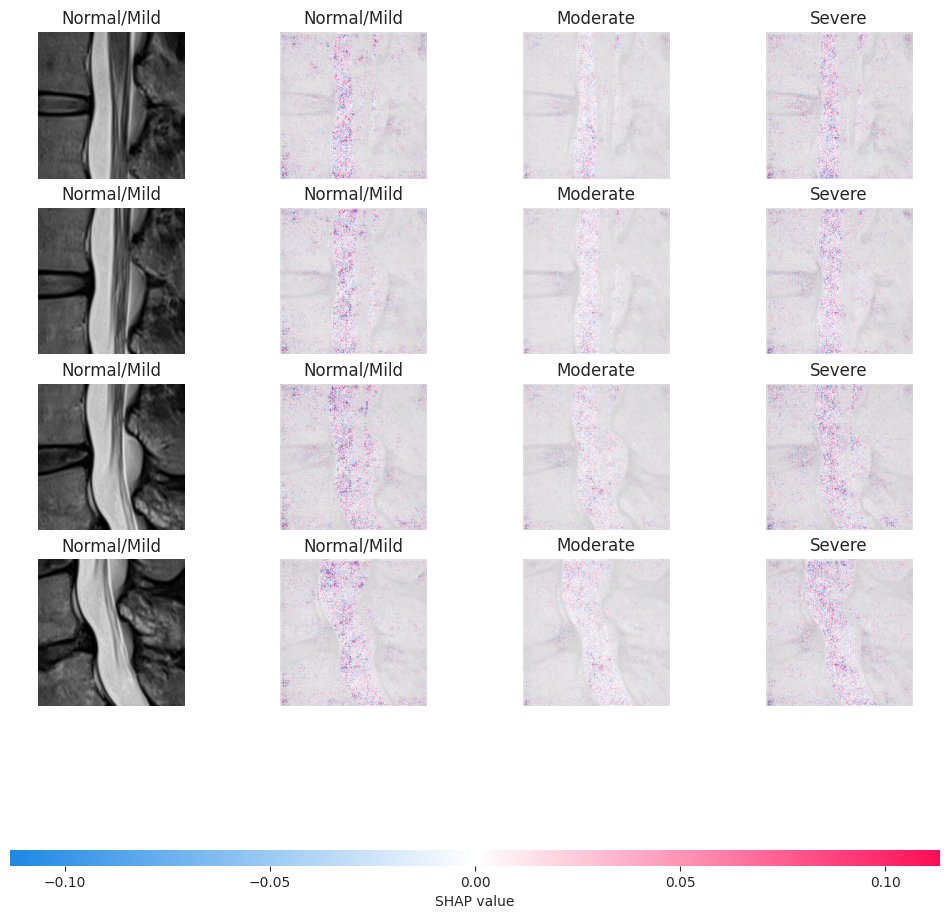

<Figure size 640x480 with 0 Axes>

Grad-CAM (primary XAI per proposal Section 3.6) is implemented separately — see that phase if present.


In [33]:
## Phase 11D — SHAP + MC-Dropout uncertainty overlay (fixed for the real single-modality LSS_Hybrid)
#
# FIX 1: DeepExplainer's additivity check raises AssertionError (not RuntimeError)
# when SHAP's DeepLIFT-style attributions don't fully reconstruct the model's
# output — which happens here because LSS_Hybrid's sigmoid-gated attention
# blending (coordinate/spatial attention gates) isn't a fully-supported op for
# SHAP's backprop rules. check_additivity=False is set as first line of defense,
# and the except clause also catches AssertionError so the GradientExplainer
# fallback actually runs if DeepExplainer still fails.
#
# FIX 2: shap.image_plot expects channel-last (H, W, C) arrays for both the
# attribution maps and the pixel values. Our model is NCHW, so shap_values
# comes back channel-first (and possibly as a single stacked array rather than
# a list, depending on SHAP version). to_channels_last_shap() normalizes both
# cases into the list-of-(N,H,W,C) format image_plot needs.
#
# FIX 3: shap.image_plot's `labels` param must be shaped (num_samples, num_outputs)
# — one class-name column per sample, repeated across the batch — not one label
# per sample. Passing [[label_per_sample]] (shape (1, N)) triggered a reshape
# ValueError whenever N wasn't divisible by the number of classes.

assert_globals_unchanged('Phase 11D')  # fail loudly if anything drifted from Phase 1
!pip install -q shap
import shap

# --- Patch torchvision EfficientNet residual add to be SHAP/hook-safe ---
from torchvision.models.efficientnet import MBConv
try:
    from torchvision.models.efficientnet import FusedMBConv
except ImportError:
    FusedMBConv = None

def _res_safe_forward(self, input):
    result = self.block(input)
    if self.use_res_connect:
        result = self.stochastic_depth(result)
        result = result + input   # out-of-place: safe under SHAP's autograd hooks
    return result

MBConv.forward = _res_safe_forward
if FusedMBConv is not None:
    FusedMBConv.forward = _res_safe_forward
print("Patched MBConv/FusedMBConv for out-of-place residual add.")


def disable_inplace_ops(model):
    n_flipped = 0
    for module in model.modules():
        if hasattr(module, 'inplace') and module.inplace:
            module.inplace = False
            n_flipped += 1
    print(f'Disabled in-place ops on {n_flipped} module(s) for SHAP compatibility.')
    return model


@torch.no_grad()
def mc_dropout_predict(model, img_tensor, n_samples=20):
    was_training = model.training
    for mod in model.modules():
        if isinstance(mod, nn.Dropout):
            mod.train()
    samples = []
    for _ in range(n_samples):
        probs = torch.softmax(model(img_tensor), dim=1).cpu().numpy()
        samples.append(probs)
    model.train(was_training)
    samples = np.stack(samples, axis=0)
    return samples.mean(axis=0), samples.std(axis=0)


def to_channels_last_shap(shap_values):
    """Normalize shap_values into a list of (N, H, W, C) arrays, regardless of
    whether SHAP returned a list of per-class NCHW arrays or a single stacked
    NCHW(+class) array."""
    if isinstance(shap_values, list):
        # list of (N, C, H, W) arrays, one per class
        return [np.transpose(sv, (0, 2, 3, 1)) for sv in shap_values]
    sv = np.asarray(shap_values)
    if sv.ndim == 5:
        # (N, C, H, W, n_classes) -> list of n_classes arrays (N, H, W, C)
        n_classes = sv.shape[-1]
        return [np.transpose(sv[..., c], (0, 2, 3, 1)) for c in range(n_classes)]
    elif sv.ndim == 4:
        # single (N, C, H, W) array -> treat as one "class"
        return [np.transpose(sv, (0, 2, 3, 1))]
    else:
        raise ValueError(f"Unexpected shap_values shape {sv.shape}")


gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = trained['Hybrid']
model.eval()
disable_inplace_ops(model)

xai_train_loader = DataLoader(CropDataset(train_crops, train=False), batch_size=16,
                              shuffle=True, num_workers=0, pin_memory=False)
xai_test_loader  = DataLoader(CropDataset(test_crops, train=False), batch_size=4,
                              shuffle=False, num_workers=0, pin_memory=False)

background_imgs, _, _, _ = next(iter(xai_train_loader))
background_imgs = background_imgs[:16].to(DEVICE)
sample_imgs, sample_labels, _, _ = next(iter(xai_test_loader))
sample_imgs = sample_imgs[:4].to(DEVICE)
sample_labels = sample_labels[:4]

shap_values = None
try:
    print("Attempting DeepExplainer...")
    explainer = shap.DeepExplainer(model, background_imgs)
    shap_values = explainer.shap_values(sample_imgs, check_additivity=False)
except (RuntimeError, AssertionError) as deep_err:
    print(f"DeepExplainer failed ({deep_err}); falling back to GradientExplainer")
    gc.collect(); torch.cuda.empty_cache()
    explainer = shap.GradientExplainer(model, background_imgs)
    shap_values = explainer.shap_values(sample_imgs)

mean_probs, std_probs = mc_dropout_predict(model, sample_imgs, n_samples=20)
for i in range(sample_imgs.shape[0]):
    pred_idx = int(mean_probs[i].argmax())
    print(f"Sample {i} | Predicted: {CLASS_NAMES[pred_idx]:<12} "
          f"Confidence={mean_probs[i][pred_idx]:.3f} Uncertainty(std)={std_probs[i][pred_idx]:.3f} "
          f"True={CLASS_NAMES[int(sample_labels[i])]}")

# --- Normalize shap_values to channel-last for image_plot ---
shap_values_cl = to_channels_last_shap(shap_values)

# --- Unnormalize the background pixel values for a clean display image ---
# (adjust mean/std here if your CropDataset uses different normalization stats)
_mean = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
_std  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
display_imgs = (sample_imgs * _std + _mean).clamp(0, 1)

# labels must be (num_samples, num_outputs): same class-name row repeated per sample
num_classes = len(shap_values_cl)
plot_labels = np.array([CLASS_NAMES[:num_classes] for _ in range(sample_imgs.shape[0])])
true_label_names = [CLASS_NAMES[int(lab)] for lab in sample_labels]

plt.figure(figsize=(12, 6))
shap.image_plot(shap_values_cl, display_imgs.permute(0, 2, 3, 1).cpu().numpy(),
                labels=plot_labels, true_labels=true_label_names)
os.makedirs(XAI_DIR, exist_ok=True)
plt.savefig(f'{XAI_DIR}/shap_uncertainty_demo.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grad-CAM (primary XAI per proposal Section 3.6) is implemented separately — see that phase if present.")

In [34]:
missing = [name for name in ['assert_globals_unchanged', 'trained', 'train_crops',
                              'test_crops', 'DEVICE', 'CLASS_NAMES', 'XAI_DIR',
                              'CropDataset', 'LSS_Hybrid']
           if name not in globals()]
print("Missing:", missing if missing else "none — safe to run Phase 11D")

Missing: none — safe to run Phase 11D


## Phase 11E — Severity → surgical risk tier rule table (feeds Step 16's PDF logic)

**Priority 4.** The classifier outputs per-condition-level severity; the
clinical report wants one "surgical risk tier" per patient. This is a rule
layer, not something the model produces — **the thresholds below are a
starting draft, not derived from clinical literature. They must be reviewed
and validated by your supervisor or a clinician before any real report uses
them.**


In [ ]:
def compute_risk_tier(study_result_df):
    """DRAFT rule set — validate thresholds with a clinician before real use."""
    sev_rank = {'Normal/Mild': 0, 'Moderate': 1, 'Severe': 2}
    ranks = study_result_df['severity'].map(sev_rank).dropna()
    if len(ranks) == 0:
        return {'tier': 'Unknown', 'reason': 'no valid predictions', 'n_severe': 0, 'n_moderate': 0}

    n_severe = int((ranks == 2).sum())
    n_moderate = int((ranks == 1).sum())

    if n_severe >= 2:
        tier, reason = 'High', f'{n_severe} severe findings across levels/conditions'
    elif n_severe == 1:
        tier, reason = 'Moderate-High', '1 severe finding'
    elif n_moderate >= 3:
        tier, reason = 'Moderate', f'{n_moderate} moderate findings'
    elif n_moderate >= 1:
        tier, reason = 'Low-Moderate', f'{n_moderate} moderate finding(s)'
    else:
        tier, reason = 'Low', 'no moderate/severe findings'
    return {'tier': tier, 'reason': reason, 'n_severe': n_severe, 'n_moderate': n_moderate}


risk = compute_risk_tier(demo_result)
print(f"Study {demo_study_id} -> Surgical risk tier: {risk['tier']}  ({risk['reason']})")
print("NOTE: thresholds are a draft placeholder — confirm with a clinician / supervisor.")


## Phase 11F — Robustness hardening for rural-hospital edge cases (Step 21)

**Priority 5.** Hardens crop loading against what the offline Django module
will actually meet on hospital laptops: missing files, corrupted DICOM headers,
and unreadably low-quality pixel data. Use `load_crop_safe` (not the original
`load_crop`) inside the real Django inference endpoint — the training pipeline
above can keep using the original since training data is already known-good.


In [37]:
def load_crop_safe(dicom_path, x, y, crop_frac=CROP_FRAC, out_size=IMG_SIZE, min_std=3.0):
    """Returns (PIL.Image or None, status). status in:
    'ok' | 'missing_file' | 'corrupt_dicom' | 'low_quality'
    Use this version (not load_crop) in the Django offline inference endpoint."""
    if not os.path.exists(dicom_path):
        return None, 'missing_file'
    try:
        d = dcm.dcmread(dicom_path)
        arr = d.pixel_array.astype(np.float32)
    except Exception:
        return None, 'corrupt_dicom'

    if arr.std() < min_std:              # near-blank / garbage pixel data
        return None, 'low_quality'

    H, W = arr.shape[:2]
    mn, mx = arr.min(), arr.max()
    arr = (arr - mn) / (mx - mn) if mx > mn else np.zeros_like(arr)
    arr = (arr * 255).astype(np.uint8)
    half = max(int(round(crop_frac * min(H, W) / 2)), 16)
    cx, cy = int(round(x)), int(round(y))
    x0, x1 = max(0, cx - half), min(W, cx + half)
    y0, y1 = max(0, cy - half), min(H, cy + half)
    crop = arr[y0:y1, x0:x1]
    if crop.size == 0:
        crop = arr[H // 2 - half:H // 2 + half, W // 2 - half:W // 2 + half]
    pil = Image.fromarray(crop).resize((out_size, out_size), Image.BILINEAR).convert('RGB')
    return pil, 'ok'


# Self-test against a few real files
for _, row in test_crops.sample(5, random_state=1).iterrows():
    _, status = load_crop_safe(row['dicom_path'], row['x'], row['y'])
    print(f"  study {row['study_id']}: status={status}")


  study 1172644546: status=ok
  study 1774588202: status=ok
  study 177339056: status=ok
  study 1009445512: status=ok
  study 2247118504: status=ok


## Phase 11G — Inference Contract: JSON I/O for the Django Backend

**Priority 2 (deployment glue).** Everything above returns Python objects
(DataFrames, dicts) meant for notebook use. Django needs one function with a
fixed JSON-in/JSON-out shape it can call from a view without touching any
notebook internals. This cell defines that single entrypoint — `run_inference_api`
— combining the study-level prediction wrapper (Phase 14C) and the risk-tier
rule (Phase 14E) into one response Django can serialize directly.

In [ ]:
def run_inference_api(study_id: int) -> dict:
    """Single entrypoint for Django. Input: study_id (int).
    Output: JSON-serializable dict -- safe to return directly from a view.
    `predictions` is None (with `is_valid_lumbar_mri=False`) when the
    MRIGatekeeper rejects the study's representative slice."""
    result_df = predict_study(quantized_student, study_id, gate=mri_gate)
    if result_df is None:
        return {
            'study_id': study_id,
            'is_valid_lumbar_mri': False,
            'predictions': None,
            'risk_tier': None,
            'rejection_reason': 'Uploaded image does not appear to be a lumbar spine MRI.',
            'model_version': 'LSS_Student-int8',
        }
    risk = compute_risk_tier(result_df)
    return {
        'study_id': study_id,
        'is_valid_lumbar_mri': True,
        'predictions': result_df.to_dict(orient='records'),
        'risk_tier': risk,
        'rejection_reason': None,
        'model_version': 'LSS_Student-int8',
    }

# Sanity check with the same demo study used earlier
print(run_inference_api(demo_study_id))

## Phase 11H — Framework-Agnostic Model Export (ONNX)

**Priority 1 (deployment blocker).** The Django backend should not require a
full PyTorch install just to run inference. Exporting to ONNX lets the backend
load the model with the lightweight `onnxruntime` package instead — this is
the actual "export" artifact the frontend/backend integration depends on, and
it must exist before Phase 14G's packaging step below can call it complete.

**Note:** dynamic-INT8-quantized modules sometimes fail ONNX export. If this
cell errors, export `student_cpu` (FP32, pre-quantization) instead.

In [39]:
!pip install -q onnxscript

In [ ]:
# 1. Export the *unquantized* (float) student model to ONNX
# CHANGED (Roadmap 7-F): dummy_input was created on CPU by default while
# student_model could still be on cuda (DEVICE) -- causing the mirror-image of the
# Phase 11C bug: "Input type (torch.FloatTensor) and weight type
# (torch.cuda.FloatTensor) should be the same". Move the model to CPU for export
# instead of moving the dummy input to cuda -- ONNX export + edge deployment should
# both be CPU-side anyway, so this also matches how the model will actually run.
student_model_cpu = student_model.to('cpu').eval()
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
torch.onnx.export(
    student_model_cpu,       # the fp32 model, NOT quantized_student -- exported on CPU
    dummy_input,
    f'{EDGE_DIR}/student_model_fp32.onnx',
    input_names=['image'], output_names=['probs'],
    dynamic_axes={'image': {0: 'batch'}, 'probs': {0: 'batch'}},
    dynamo=False,
    opset_version=13
)

# 2. Quantize the ONNX model using ONNX Runtime's quantization tools
from onnxruntime.quantization import quantize_dynamic, QuantType

quantize_dynamic(
    model_input=f'{EDGE_DIR}/student_model_fp32.onnx',
    model_output=f'{EDGE_DIR}/student_model.onnx',
    weight_type=QuantType.QInt8   # matches dynamic quantization behavior
)

print(f"Exported quantized ONNX model to {EDGE_DIR}/student_model.onnx")

## Phase 11H2 — Export the MRI Gatekeeper (ONNX + reference stats)

**Priority 1 (deployment blocker, same tier as 11H).** The severity models are
useless if run on the wrong kind of image, so the gate has to ship to Django
too. Two artifacts, mirroring the pattern above: `gatekeeper_backbone.onnx`
(the frozen MobileNetV3-Small feature extractor) and `gate_config.json`
(reference mean/std + reject threshold, written by `MRIGatekeeper.save`) — the
Mahalanobis-style distance check itself is cheap enough to redo in plain numpy
inside Django, no need to export that part as a graph.


In [ ]:
gate_dummy = torch.randn(1, 3, mri_gate.img_size, mri_gate.img_size).to(DEVICE)
torch.onnx.export(
    mri_gate.backbone, gate_dummy,
    f'{EDGE_DIR}/gatekeeper_backbone.onnx',
    input_names=['image'], output_names=['embedding'],
    dynamic_axes={'image': {0: 'batch'}, 'embedding': {0: 'batch'}}
)
mri_gate.save(f'{EDGE_DIR}/gate_config.json')
print(f"Exported ONNX gatekeeper to {EDGE_DIR}/gatekeeper_backbone.onnx")
print(f"Exported gate reference stats to {EDGE_DIR}/gate_config.json")


## Phase 11J — Export inference config for the Django backend

**Priority 1 (deployment blocker).** `student_model.onnx` alone isn't enough —
Django's `api/inference.py` needs the exact preprocessing constants
(crop fraction, input size, normalization stats) and class/condition names
used at training time, or its crops won't match what the model was trained
on. This writes that single `model_config.json` next to the ONNX file.

In [ ]:
model_config = {
    'IMG_SIZE': IMG_SIZE,
    'CROP_FRAC': CROP_FRAC,
    'IMAGENET_MEAN': IMAGENET_MEAN,
    'IMAGENET_STD': IMAGENET_STD,
    'CLASS_NAMES': CLASS_NAMES,
    'CONDITIONS': [
        'Spinal Canal Stenosis',
        'Left Neural Foraminal Narrowing',
        'Right Neural Foraminal Narrowing',
        'Left Subarticular Stenosis',
        'Right Subarticular Stenosis',
    ],
    'MODEL_VERSION': 'LSS_Student-int8-v0.1',
}
with open(f'{EDGE_DIR}/model_config.json', 'w') as f:
    json.dump(model_config, f, indent=2)
print(f"Exported config to {EDGE_DIR}/model_config.json")
print(json.dumps(model_config, indent=2))

# Kaggle has no access to your local Django backend folder -- artifacts are left
# in EDGE_DIR (under /kaggle/working) instead of being copied automatically.
# After this notebook finishes: commit the notebook, then from the "Output" tab
# download student_model.onnx, model_config.json, gatekeeper_backbone.onnx, and
# gate_config.json, and drop them into your local lsd-webapp/backend/ml_artifacts/
# folder by hand (or script it with the Kaggle API's `kaggle kernels output` command
# from your own machine, once you know this notebook's slug).
print(f"\nArtifacts ready for manual download from EDGE_DIR: {EDGE_DIR}")
print("  - student_model.onnx")
print("  - model_config.json")
print("  - gatekeeper_backbone.onnx")
print("  - gate_config.json")

## Phase 11I — Standalone Reload Test (proves the export is self-contained)

**Priority 2 (verification).** Confirms the ONNX file works using *only* the
exported artifact — no training-time variables, no notebook state. This is
the same test Django's deployment environment will effectively run: load
`student_model.onnx` cold, and get a prediction back. If this cell fails,
the export is not actually portable yet.

In [ ]:
import onnxruntime as ort
sess = ort.InferenceSession(f'{EDGE_DIR}/student_model.onnx')
dummy = np.random.randn(1, 3, IMG_SIZE, IMG_SIZE).astype(np.float32)
out = sess.run(None, {'image': dummy})
print("ONNX inference OK, output shape:", out[0].shape)

# Phase 12 (Test-Time Augmentation)

In [ ]:
## Phase 12 — Test-Time Augmentation (TTA)
# Averages predictions across TTA_VIEWS deterministic augmented views of each crop.
# Report this ALONGSIDE (not instead of) the Phase 10 single-view Table 2, so you can
# show the accuracy gain TTA buys for the dissertation write-up.

_tta_transforms = [
    T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomHorizontalFlip(1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomRotation((5, 5)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomRotation((-5, -5)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.Resize((int(IMG_SIZE*1.05), int(IMG_SIZE*1.05))), T.CenterCrop(IMG_SIZE), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
][:TTA_VIEWS]

@torch.no_grad()
def predict_tta(model, pil_img, device=DEVICE):
    model.eval()
    views = torch.stack([tf(pil_img) for tf in _tta_transforms]).to(device)
    probs = torch.softmax(model(views), dim=1).mean(dim=0)
    return probs.cpu().numpy()

@torch.no_grad()
def evaluate_tta(model, crops_df):
    model.eval()
    preds, labels, probs_all = [], [], []
    for r in crops_df.itertuples(index=False):
        try:
            img = load_crop(r.dicom_path, r.x, r.y)
        except Exception:
            continue
        p = predict_tta(model, img)
        preds.append(int(p.argmax())); labels.append(int(r.label)); probs_all.append(p)
    labels = np.array(labels); preds = np.array(preds); probs_all = np.array(probs_all)
    acc = accuracy_score(labels, preds)
    f1m = f1_score(labels, preds, average='macro')
    kappa = cohen_kappa_score(labels, preds)
    wll = weighted_log_loss(labels, probs_all)
    print(f"TTA ({TTA_VIEWS} views) Test results: acc={acc*100:.2f}%  macro-F1={f1m:.4f}  kappa={kappa:.4f}  WLL={wll:.4f}")
    print(classification_report(labels, preds, target_names=CLASS_NAMES))
    return acc, f1m, kappa, wll, preds, labels, probs_all

print("Running TTA evaluation on the primary Hybrid model (compare against Phase 10's single-view table)...")
tta_results = evaluate_tta(trained['Hybrid'], test_crops)